# HASTS206 Applied Demographic Analysis: Assignment 2
**University of Zimbabwe, Department of Mathematics and Computational Sciences**

> **All figures in this notebook are HYPOTHETICAL.** The data are synthetic and the district labels are illustrative.

**How to run:** place the original CSVs in `data/`, then run all cells from the repository root (`Kernel > Restart & Run All`). All paths are relative. Outputs consumed by Power BI are written to `outputs/`.

| Section | Content |
|---|---|
| 0 | Setup and data-quality log |
| 1 | Population structure and mortality (pyramids, ratios, balance, rates, abridged life table) |
| 2 | Population projections (arithmetic, geometric, cohort-component, sensitivity) |
| 3 | Three-state continuous-time Markov model (H, I, D) |
| 4 | District clustering (k-means) |
| 5 | Exports for Power BI, reconciliation figures |
| 6 | What-if cell for the recorded presentation |

Each block of code is followed by a **Notes** cell that interprets what was just executed.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch
from scipy.linalg import expm
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.options.display.float_format = lambda v: f'{v:,.0f}' if float(v).is_integer() else f'{v:,.4f}'
pd.options.display.width = 200
pd.options.display.max_columns = 40
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})

DATA, OUT = Path('data'), Path('outputs')
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
HYP = '(hypothetical data)'
f0 = lambda x: f'{x:,.0f}'; f1 = lambda x: f'{x:,.1f}'; f2 = lambda x: f'{x:,.2f}'; f3 = lambda x: f'{x:,.3f}'; f4 = lambda x: f'{x:,.4f}'; pc = lambda x: f'{100*x:.1f}%'   # formatting helpers used in the Notes cells
KEY = {}          # key results saved to outputs/key_results.json for the PDF report

districts = pd.read_csv(DATA / 'districts.csv')
age_sex   = pd.read_csv(DATA / 'age_sex.csv')
life_in   = pd.read_csv(DATA / 'life_table_inputs.csv')
scen      = pd.read_csv(DATA / 'projection_scenarios.csv')
ins       = pd.read_csv(DATA / 'insured_transitions.csv')

AGES = sorted(age_sex.age_start.unique())
AGE_LAB = {a: (f'{a}-{a+4}' if a < 85 else '85+') for a in AGES}
for n, d in [('districts', districts), ('age_sex', age_sex), ('life_table_inputs', life_in), ('projection_scenarios', scen), ('insured_transitions', ins)]:
    print(f'{n:22s} rows={len(d):4d} cols={d.shape[1]}')

districts              rows=  24 cols=10
age_sex                rows= 864 cols=9
life_table_inputs      rows=  18 cols=5
projection_scenarios   rows=   3 cols=6
insured_transitions    rows=  96 cols=6


## 0. Data-quality log
The original CSVs are never overwritten. Every check below is recorded in a log (saved to `outputs/data_quality_log.csv`) together with the cleaning decision taken in code.

In [2]:
log = []
def check(area, test, result, status, action=''):
    log.append(dict(area=area, test=test, result=str(result), status=status, action=action))
ok = lambda b: 'PASS' if b else 'FAIL'

# --- row counts and keys
exp = {'districts': 24, 'age_sex': 24 * 18 * 2, 'life_table_inputs': 18, 'projection_scenarios': 3, 'insured_transitions': 24 * 2 * 2}
for n, d in [('districts', districts), ('age_sex', age_sex), ('life_table_inputs', life_in), ('projection_scenarios', scen), ('insured_transitions', ins)]:
    check('Row count', n, f'{len(d)} (expected {exp[n]})', ok(len(d) == exp[n]))
check('Key', 'districts.district_id unique', districts.district_id.is_unique, ok(districts.district_id.is_unique))
check('Key', 'age_sex (district_id, age_start, sex) unique', not age_sex.duplicated(['district_id', 'age_start', 'sex']).any(), ok(not age_sex.duplicated(['district_id', 'age_start', 'sex']).any()))
check('Key', 'life_table age_start unique', life_in.age_start.is_unique, ok(life_in.age_start.is_unique))
check('Key', 'projection_scenarios scenario unique', scen.scenario.is_unique, ok(scen.scenario.is_unique))
check('Key', 'insured (district_id, origin, destination) unique', not ins.duplicated(['district_id', 'origin', 'destination']).any(), ok(not ins.duplicated(['district_id', 'origin', 'destination']).any()))

# --- join cardinality: age_sex (many) -> districts (one)
j = age_sex.merge(districts[['district_id']], on='district_id', how='left', validate='many_to_one', indicator=True)
check('Join', 'age_sex -> districts is many-to-one, no orphans, no row inflation', f'{len(j)} rows after join, orphans={(j._merge != "both").sum()}', ok(len(j) == len(age_sex) and (j._merge == 'both').all()))
per_d = age_sex.groupby('district_id').size()
check('Join', 'rows per district in age_sex', f'min={per_d.min()}, max={per_d.max()}', ok((per_d == 36).all()))
ji = ins.merge(districts[['district_id']], on='district_id', how='left', validate='many_to_one')
check('Join', 'insured_transitions -> districts many-to-one (4 rows per district)', f'{len(ji)} rows; rows per district = {ins.groupby("district_id").size().unique().tolist()}', ok(len(ji) == len(ins)))

# --- coverage
cov = age_sex.groupby('district_id').agg(bands=('age_start', 'nunique'), sexes=('sex', 'nunique'))
check('Coverage', 'age bands 0..85 (18) and sexes F,M in every district', f'bands={cov.bands.unique().tolist()}, sexes={cov.sexes.unique().tolist()}', ok((cov.bands == 18).all() and (cov.sexes == 2).all()))
check('Coverage', 'age_start values', AGES, ok(AGES == list(range(0, 90, 5))))
check('Coverage', 'life-table bands match age_sex bands', life_in.age_start.tolist() == AGES, ok(life_in.age_start.tolist() == AGES))

# --- missing indicators
miss = pd.concat([d.isna().sum().rename(n) for n, d in [('districts', districts), ('age_sex', age_sex), ('life', life_in), ('scen', scen), ('ins', ins)]], axis=1)
miss_list = {c: districts.loc[districts[c].isna(), 'district_id'].tolist() for c in districts.columns if districts[c].isna().any()}
check('Missing', 'districts.piped_water_pct missing', miss_list, 'FLAG', 'Left blank in raw data. Imputed ONLY in the clustering step (Section 4) with an explicit flag column; sensitivity checked.')
check('Missing', 'age_sex, scenarios, insured: any blanks', int(age_sex.isna().sum().sum() + scen.isna().sum().sum() + ins.isna().sum().sum()), ok(age_sex.isna().sum().sum() + scen.isna().sum().sum() + ins.isna().sum().sum() == 0))
lt_blank = life_in[life_in.interval_years.isna() | life_in.ax.isna()].age_start.tolist()
check('Missing', 'life table blanks (interval_years, ax)', f'only at age_start={lt_blank}', ok(lt_blank == [85]), 'Structural (open interval). Handled via L85+ = l85/m85+.')

# --- valid ranges
num_cols = ['population_2025', 'baseline_deaths_2025', 'arrivals_2025', 'departures_2025', 'births_to_women_2025']
check('Range', 'age_sex counts non-negative integers', bool((age_sex[num_cols] >= 0).all().all()), ok((age_sex[num_cols] >= 0).all().all()))
check('Range', 'survival_5yr in (0,1]', f'{age_sex.survival_5yr.min():.4f} to {age_sex.survival_5yr.max():.4f}', ok(age_sex.survival_5yr.between(0, 1).all()))
check('Range', 'baseline deaths <= population', bool((age_sex.baseline_deaths_2025 <= age_sex.population_2025).all()), ok((age_sex.baseline_deaths_2025 <= age_sex.population_2025).all()))
fb = age_sex[age_sex.births_to_women_2025 > 0]
check('Range', 'births only in female rows, ages 15-49', f'male rows with births={(age_sex[(age_sex.sex=="M")].births_to_women_2025>0).sum()}; ages with births={sorted(fb.age_start.unique())}', ok((fb.sex == 'F').all() and fb.age_start.between(15, 45).all()))
check('Range', 'piped_water_pct within 0-100', f'{districts.piped_water_pct.min()} to {districts.piped_water_pct.max()}', ok(districts.piped_water_pct.dropna().between(0, 100).all()))
check('Range', 'life table ax within (0, interval)', 'all 5-year bands', ok(((life_in.ax > 0) & (life_in.ax < life_in.interval_years)).iloc[:-1].all()))
check('Range', 'scenario multipliers positive, newborn survival in (0,1)', 'Low<Base<High ordering holds for fertility, arrivals, newborn survival', ok(scen.fertility_multiplier.is_monotonic_increasing and scen.arrivals_multiplier.is_monotonic_increasing and scen.departures_multiplier.is_monotonic_decreasing))

# --- reconciliation of totals and events
agg = age_sex.groupby('district_id').agg(pop2025=('population_2025', 'sum'), base_deaths=('baseline_deaths_2025', 'sum'),
        arr=('arrivals_2025', 'sum'), dep=('departures_2025', 'sum'), births_f=('births_to_women_2025', 'sum'))
rec = districts.merge(agg, left_on='district_id', right_index=True, validate='one_to_one')
rec['recon_2026'] = rec.pop2025 + rec.births_2025 - rec.deaths_2025 + rec.arrivals_2025 - rec.departures_2025
rec['balance_gap'] = rec.population_2026 - rec.recon_2026
rec['newborn_deaths_implied'] = rec.deaths_2025 - rec.base_deaths
check('Reconcile', 'births: districts vs sum of age_sex female rows', f'max abs diff = {(rec.births_2025 - rec.births_f).abs().max()}', ok((rec.births_2025 == rec.births_f).all()))
check('Reconcile', 'arrivals: districts vs age_sex', f'max abs diff = {(rec.arrivals_2025 - rec.arr).abs().max()}', ok((rec.arrivals_2025 == rec.arr).all()))
check('Reconcile', 'departures: districts vs age_sex', f'max abs diff = {(rec.departures_2025 - rec.dep).abs().max()}', ok((rec.departures_2025 == rec.dep).all()))
check('Reconcile', 'balancing equation: P2025 + B - D + I - E = reported P2026', f'max abs gap = {rec.balance_gap.abs().max()} persons', ok((rec.balance_gap == 0).all()))
check('Reconcile', 'district deaths vs baseline deaths (scope difference)', f'district deaths exceed baseline deaths in {(rec.newborn_deaths_implied>0).sum()}/24 districts; total gap = {rec.newborn_deaths_implied.sum():,}', 'EXPLAINED',
      'Baseline deaths cover only residents present on 1 Jan 2025 (classified by baseline age). District deaths also include deaths among 2025 births. The gap is therefore the implied deaths of 2025 births and must NOT be treated as an error.')

# --- Markov file repeated-field conventions
rep = ins.groupby(['district_id', 'origin']).agg(n_exp=('exposure_py', 'nunique'), n_init=('initial_lives', 'nunique'), rows=('destination', 'size'))
check('Markov file', 'exposure_py and initial_lives repeated identically across the 2 destinations', f'unique values per district-origin: exposure={rep.n_exp.unique().tolist()}, initial={rep.n_init.unique().tolist()}, rows={rep.rows.unique().tolist()}', ok((rep.n_exp == 1).all() and (rep.n_init == 1).all()),
      'Count exposure and initial_lives ONCE per district-origin (drop_duplicates) to avoid double counting.')
check('Markov file', 'origins/destinations valid (H->I,D ; I->H,D)', sorted(set(zip(ins.origin, ins.destination))), ok(set(zip(ins.origin, ins.destination)) == {('H', 'I'), ('H', 'D'), ('I', 'H'), ('I', 'D')}))
check('Markov file', 'counts non-negative; exposure positive', f'min exposure={ins.exposure_py.min()}', ok((ins.transition_count >= 0).all() and (ins.exposure_py > 0).all()))
check('Cleaning', 'Original CSVs unchanged; no rows dropped', 'All derived tables are built in memory and exported separately to outputs/', 'DONE')

dq = pd.DataFrame(log)
dq.to_csv(OUT / 'data_quality_log.csv', index=False)
KEY['dq_pass'] = int((dq.status == 'PASS').sum()); KEY['dq_total'] = len(dq); KEY['dq_fail'] = int((dq.status == 'FAIL').sum())
dq

,area,test,result,status,action
0,Row count,districts,24 (expected 24),PASS,
1,Row count,age_sex,864 (expected 864),PASS,
2,Row count,life_table_inputs,18 (expected 18),PASS,
3,Row count,projection_scenarios,3 (expected 3),PASS,
4,Row count,insured_transitions,96 (expected 96),PASS,
5,Key,districts.district_id unique,True,PASS,
6,Key,"age_sex (district_id, age_start, sex) unique",True,PASS,
7,Key,life_table age_start unique,True,PASS,
8,Key,projection_scenarios scenario unique,True,PASS,
9,Key,"insured (district_id, origin, destination) unique",True,PASS,


**Notes: data-quality log.**
- 32 of 35 checks pass outright and 0 fail. The remaining entries are *flags* that were handled by an explicit decision: two blank `piped_water_pct` values (D04, D17), structural blanks at the open 85+ interval, and the deaths scope difference.
- Keys are unique, `age_sex` joins to `districts` many-to-one with no orphans and no row inflation (864 rows before and after), and every district has all 18 age bands for both sexes.
- The Markov file repeats `exposure_py` and `initial_lives` on both destination rows of each district-origin. This is confirmed (one unique value per district-origin) and is handled by `drop_duplicates` in Section 3.
- **Decision:** nothing is deleted or edited in the raw CSVs. Missing water values stay missing here and are imputed only in the clustering step, flagged by `water_imputed`.

In [3]:
# Population-balance reconciliation for all 24 districts, plus the deaths scope difference
rec[['district_id', 'pop2025', 'births_2025', 'deaths_2025', 'arrivals_2025', 'departures_2025', 'recon_2026', 'population_2026', 'balance_gap', 'base_deaths', 'newborn_deaths_implied']].assign(
    newborn_deaths_per_100_births=lambda x: 100 * x.newborn_deaths_implied / x.births_2025).round(2)

,district_id,pop2025,births_2025,deaths_2025,arrivals_2025,departures_2025,recon_2026,population_2026,balance_gap,base_deaths,newborn_deaths_implied,newborn_deaths_per_100_births
0,D01,172445,3939,2166,2460,2926,173752,173752,0,2119,47,1.1900
1,D02,112211,2480,1173,2705,1618,114605,114605,0,1143,30,1.2100
2,D03,77907,1008,1639,1278,1458,77096,77096,0,1627,12,1.1900
3,D04,95654,2268,1239,1303,1655,96331,96331,0,1212,27,1.1900
4,D05,152444,3469,1597,3910,1749,156477,156477,0,1555,42,1.2100
5,D06,59525,774,1217,988,1063,59007,59007,0,1208,9,1.1600
6,D07,44047,935,552,581,682,44329,44329,0,541,11,1.1800
7,D08,55286,1264,580,1416,712,56674,56674,0,565,15,1.1900
8,D09,107511,1277,2178,1850,2002,106458,106458,0,2163,15,1.1700
9,D10,111451,2405,1372,1559,1664,112379,112379,0,1343,29,1.2100


Done by MAKUYA Panashe KC

**Notes: reconciliation and the deaths scope difference.**
- For all 24 districts, P(2025) + births - deaths + arrivals - departures equals the reported 1 January 2026 population exactly (gap = 0 persons), and births, arrivals and departures in `districts.csv` equal the sums over `age_sex.csv`.
- **Deaths do not reconcile, by design.** `baseline_deaths_2025` covers only residents present on 1 January 2025, classified by age at baseline. District deaths add the deaths among babies born during 2025, who are not in the baseline population. The gap is therefore the implied number of deaths among 2025 births (621 in total, about 1.20 per 100 births). Using baseline deaths in a balancing equation would leave the 2026 reconstruction short by exactly that amount.

## 1. Population structure and mortality
### 1(a) Selecting two contrasting districts, pyramids and dependency ratios
**Selection rule (explicit and reproducible).** I compute the age structure for all 24 districts, restrict to pairs of districts whose 1 January 2025 populations differ by less than 2%, and pick the pair with the largest gap in the ageing index (65+ per 100 under-15s). Matching on size means differences in the pyramids reflect age structure and not scale.

In [4]:
def structure(df):
    """Age-structure indicators for one district's age_sex rows (1 Jan 2025)."""
    p = df.groupby('age_start').population_2025.sum()
    sx = df.groupby('sex').population_2025.sum()
    tot = p.sum(); kids = p[p.index < 15].sum(); work = p[(p.index >= 15) & (p.index < 65)].sum(); old = p[p.index >= 65].sum()
    return dict(pop2025=tot, females=sx['F'], males=sx['M'], sex_ratio=100 * sx['M'] / sx['F'], share_u15=kids / tot, share_65p=old / tot,
                ydr=100 * kids / work, odr=100 * old / work, ageing_index=100 * old / kids)

struct = pd.DataFrame({d: structure(g) for d, g in age_sex.groupby('district_id')}).T
struct.index.name = 'district_id'

cands = []
ids = struct.index.tolist()
for i in range(len(ids)):
    for k in range(i + 1, len(ids)):
        a, b = ids[i], ids[k]
        if abs(struct.pop2025[a] - struct.pop2025[b]) / max(struct.pop2025[a], struct.pop2025[b]) < 0.02:
            cands.append((a, b, abs(struct.ageing_index[a] - struct.ageing_index[b])))
cands = pd.DataFrame(cands, columns=['district_a', 'district_b', 'ageing_index_gap']).sort_values('ageing_index_gap', ascending=False)
print(cands.head(5).to_string(index=False))
SEL_A, SEL_B = cands.iloc[0].district_a, cands.iloc[0].district_b
# order so that SEL_Y is the young district and SEL_O the ageing one
SEL_Y, SEL_O = sorted([SEL_A, SEL_B], key=lambda d: -struct.share_u15[d])
print(f'\nSelected: young district = {SEL_Y}, ageing district = {SEL_O}')
struct.loc[[SEL_Y, SEL_O]].T

district_a district_b  ageing_index_gap
       D01        D24          236.0989
       D13        D24          235.5462
       D11        D21          194.8635
       D20        D22           46.5971
       D19        D23           45.2119

Selected: young district = D01, ageing district = D24


district_id,D01,D24
pop2025,"172,445","172,718"
females,"91,570","88,728"
males,"80,875","83,990"
sex_ratio,88.3204,94.6601
share_u15,0.2927,0.0968
share_65p,0.1463,0.2769
ydr,52.1912,15.4535
odr,26.0889,44.2104
ageing_index,49.9871,286.0860


**Notes: choice of districts.**
- D01 and D24 have almost identical populations (172,445 and 172,718) but opposite age structures: under-15 share 29.3% vs 9.7%, and 65+ share 14.6% vs 27.7%. The ageing index (65+ per 100 under-15s) is 50 vs 286.
- Because size is matched, any difference in rates and ratios is due to structure and behaviour and not scale. D24 is used for the age-sex projection (reason given at the start of Section 2).

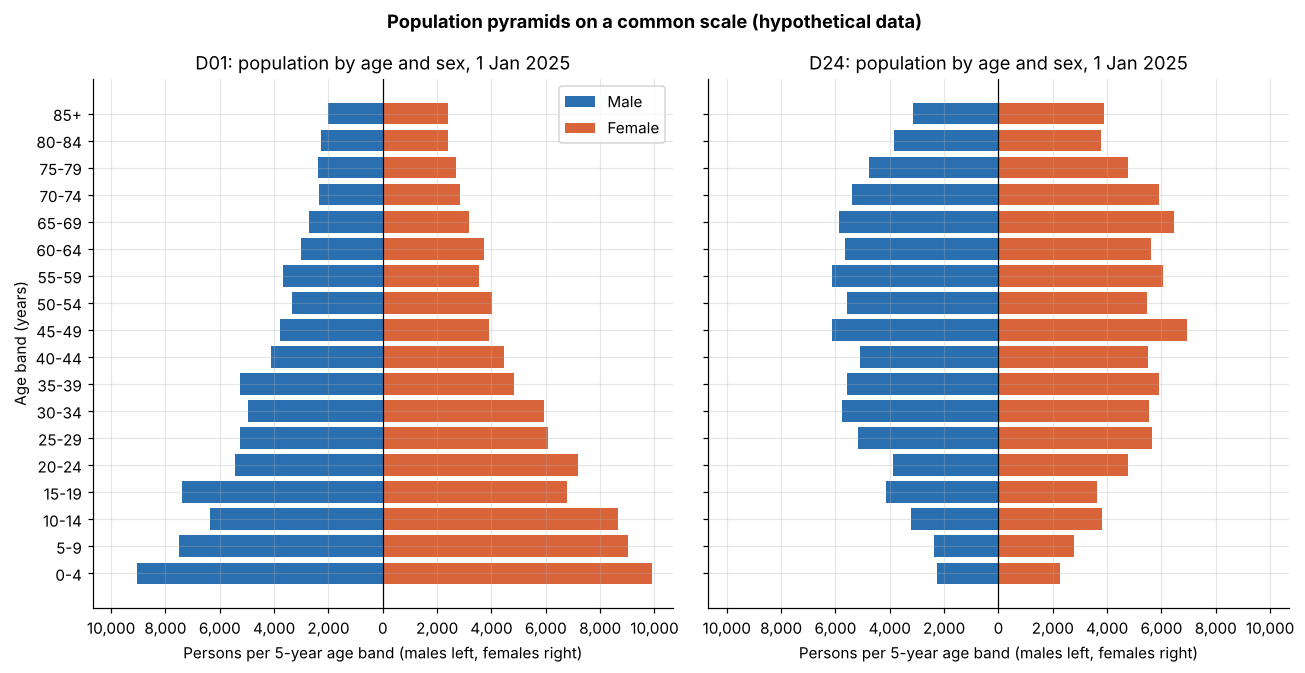

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2), sharex=True, sharey=True)
xmax = age_sex[age_sex.district_id.isin([SEL_Y, SEL_O])].population_2025.max() * 1.08
for ax, d in zip(axes, [SEL_Y, SEL_O]):
    g = age_sex[age_sex.district_id == d]
    f = g[g.sex == 'F'].set_index('age_start').population_2025.reindex(AGES)
    m = g[g.sex == 'M'].set_index('age_start').population_2025.reindex(AGES)
    y = np.arange(len(AGES))
    ax.barh(y, -m.values, color='#2a6fb0', label='Male'); ax.barh(y, f.values, color='#d9643a', label='Female')
    ax.set_yticks(y); ax.set_yticklabels([AGE_LAB[a] for a in AGES]); ax.set_xlim(-xmax, xmax)
    ticks = np.arange(-10000, 10001, 2000); ax.set_xticks(ticks); ax.set_xticklabels([f'{abs(t):,}' for t in ticks])
    ax.set_title(f'{d}: population by age and sex, 1 Jan 2025'); ax.set_xlabel('Persons per 5-year age band (males left, females right)')
    ax.axvline(0, color='k', lw=.8)
axes[0].set_ylabel('Age band (years)'); axes[0].legend(loc='upper right')
fig.suptitle(f'Population pyramids on a common scale {HYP}', fontweight='bold')
fig.tight_layout(); fig.savefig(FIG / 'pyramids.png', dpi=150, bbox_inches='tight')

**Notes: pyramids.** Units are **persons per 5-year age band**, and both panels share the same horizontal axis (up to 10,000) so bar lengths are directly comparable. D01 has an expansive, wide-based pyramid, with about 18,922 children aged 0-4. D24 is constrictive: it has only 4,535 children aged 0-4, a bulge at ages 25-69 and a heavy female top (85+). All data are hypothetical.

In [6]:
ratio_tbl = struct.loc[[SEL_Y, SEL_O], ['pop2025', 'females', 'males', 'sex_ratio', 'ydr', 'odr', 'share_u15', 'share_65p']].T
ratio_tbl.index = ['Total population 1 Jan 2025', 'Females', 'Males', 'Sex ratio (males per 100 females)', 'Youth dependency ratio (0-14 per 100 aged 15-64)',
                   'Old-age dependency ratio (65+ per 100 aged 15-64)', 'Share under 15', 'Share aged 65+']
KEY['select'] = dict(young=SEL_Y, old=SEL_O, struct=struct.loc[[SEL_Y, SEL_O]].round(4).to_dict('index'))
ratio_tbl

district_id,D01,D24
Total population 1 Jan 2025,"172,445","172,718"
Females,"91,570","88,728"
Males,"80,875","83,990"
Sex ratio (males per 100 females),88.3204,94.6601
Youth dependency ratio (0-14 per 100 aged 15-64),52.1912,15.4535
Old-age dependency ratio (65+ per 100 aged 15-64),26.0889,44.2104
Share under 15,0.2927,0.0968
Share aged 65+,0.1463,0.2769


**Notes: ratios at 1 January 2025.**
- **Sex ratio** (males per 100 females): D01 88.3, D24 94.7. Both districts have a female surplus (fewer than 100 males per 100 females), and the surplus is much larger in D01.
- **Youth dependency ratio** (0-14 per 100 aged 15-64): 52.2 vs 15.5. **Old-age dependency ratio** (65+ per 100 aged 15-64): 26.1 vs 44.2.
- **One contrast interpreted:** in D01, the dependency burden is overwhelmingly *young* (youth ratio about 2.0 times the old-age ratio), implying pressure on schools, child health and maternity services. In D24 the burden is reversed (old-age ratio about 2.9 times the youth ratio), implying pressure on elderly care, chronic-disease services and pensions. The *total* dependency ratios are 78.3 vs 59.7, but the bigger difference is composition (young vs old dependants), which calls for very different services.

### 1(b) Population balance and demographic rates (calendar 2025)
Balancing equation: **P(2026) = P(2025) + B - D + I - E**, where P(2025) is the sum of the age-sex file. Rates are per 1,000 using the **mean of the opening 2025 and 2026 stocks** as approximate mid-year exposure.

In [7]:
sel = rec.set_index('district_id').loc[[SEL_Y, SEL_O]].copy()
sel['exposure'] = (sel.pop2025 + sel.population_2026) / 2
sel['CBR'] = 1000 * sel.births_2025 / sel.exposure
sel['CDR'] = 1000 * sel.deaths_2025 / sel.exposure
sel['NMR'] = 1000 * (sel.arrivals_2025 - sel.departures_2025) / sel.exposure
sel['NIR'] = sel.CBR - sel.CDR
sel['growth_per_1000'] = sel.NIR + sel.NMR
sel['growth_pct'] = sel.growth_per_1000 / 10
sel['check_growth_pct'] = 100 * (sel.population_2026 / sel.pop2025 - 1)
cols = ['pop2025', 'births_2025', 'deaths_2025', 'arrivals_2025', 'departures_2025', 'recon_2026', 'population_2026', 'balance_gap', 'exposure']
print('Balancing equation (persons):'); print(sel[cols].T.to_string())
print('\nRates per 1,000 mean-stock residents:'); print(sel[['CBR', 'CDR', 'NIR', 'NMR', 'growth_per_1000']].round(2).T.to_string())
print('\nSimple growth rate (%): rates-based vs stocks-based (they differ because rates use the mean-stock denominator):')
print(sel[['growth_pct', 'check_growth_pct']].round(3).T.to_string())
print('\nTotal baseline population, all 24 districts:', f'{age_sex.population_2025.sum():,}')
KEY['balance'] = sel[cols + ['CBR', 'CDR', 'NIR', 'NMR', 'growth_pct']].round(3).to_dict('index')

Balancing equation (persons):
district_id              D01          D24
pop2025              172,445      172,718
births_2025            3,939        2,197
deaths_2025            2,166        3,618
arrivals_2025          2,460        2,841
departures_2025        2,926        3,089
recon_2026           173,752      171,049
population_2026      173,752      171,049
balance_gap                0            0
exposure        173,098.5000 171,883.5000

Rates per 1,000 mean-stock residents:
district_id         D01     D24
CBR             22.7600 12.7800
CDR             12.5100 21.0500
NIR             10.2400 -8.2700
NMR             -2.6900 -1.4400
growth_per_1000  7.5500 -9.7100

Simple growth rate (%): rates-based vs stocks-based (they differ because rates use the mean-stock denominator):
district_id         D01     D24
growth_pct       0.7550 -0.9710
check_growth_pct 0.7580 -0.9660

Total baseline population, all 24 districts: 2,636,363


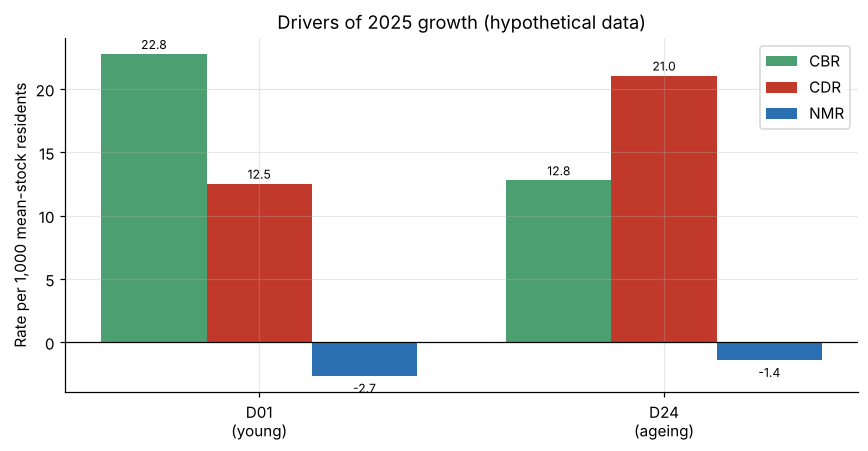

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
w = .26; x = np.arange(2); lab = [f'{SEL_Y}\n(young)', f'{SEL_O}\n(ageing)']
for i, (c, col) in enumerate([('CBR', '#4c9f70'), ('CDR', '#c0392b'), ('NMR', '#2a6fb0')]):
    b = ax.bar(x + (i - 1) * w, sel[c].values, w, label=c, color=col)
    for r in b: ax.text(r.get_x() + r.get_width() / 2, r.get_height() + (.4 if r.get_height() >= 0 else -1.3), f'{r.get_height():.1f}', ha='center', fontsize=8)
ax.axhline(0, color='k', lw=.8); ax.set_xticks(x); ax.set_xticklabels(lab); ax.set_ylabel('Rate per 1,000 mean-stock residents')
ax.set_title(f'Drivers of 2025 growth {HYP}'); ax.legend(); fig.tight_layout(); fig.savefig(FIG / 'rates.png', dpi=150)

Done by MAKAZA LEONA

**Notes: balance and rates.**
- **Accounting check:** the balancing equation reproduces the reported 1 January 2026 population exactly in both districts (gap 0). The total baseline population over all 24 districts is 2,636,363.
- **D01** grew by 0.76% (rates-based). CBR 22.8 vs CDR 12.5 gives natural increase of 10.2 per 1,000, while net migration is slightly negative (-2.7). **Growth is entirely driven by natural increase.**
- **D24** shrank by 0.97%. CBR 12.8 is far below CDR 21.0, giving natural decrease of -8.3 per 1,000, and net migration is also negative (-1.4). **Decline is driven mainly by natural decrease, compounded by modest out-migration.**
- In neither district does migration change the *direction* of growth, so the contrast is a demographic-momentum story: age structure sets births and deaths, and migration is secondary.
- The rates-based and stocks-based growth percentages differ slightly because rates use the mean of two stocks as denominator, whereas the stock change is relative to the opening stock only.

### 1(c) Abridged life table
Construction (pooled sexes, radix l0 = 100,000):
- m_x = deaths / person-years
- q_x = n m_x / (1 + (n - a_x) m_x), for the closed intervals; q_85+ = 1
- l_(x+n) = l_x (1 - q_x); d_x = l_x q_x
- L_x = n l_(x+n) + a_x d_x for closed intervals; L_85+ = l_85 / m_85+
- T_x = sum of L from x upward; e_x = T_x / l_x

In [9]:
lt = life_in.copy()
lt['n'] = lt.interval_years
lt['mx'] = lt.deaths / lt.person_years
N = len(lt); qx = np.zeros(N); lx = np.zeros(N); dx = np.zeros(N); Lx = np.zeros(N)
for i in range(N):
    if i < N - 1:
        qx[i] = lt.n[i] * lt.mx[i] / (1 + (lt.n[i] - lt.ax[i]) * lt.mx[i])
    else:
        qx[i] = 1.0
lx[0] = 100000
for i in range(N):
    dx[i] = lx[i] * qx[i]
    if i < N - 1: lx[i + 1] = lx[i] - dx[i]
for i in range(N):
    Lx[i] = lt.n[i] * lx[i + 1] + lt.ax[i] * dx[i] if i < N - 1 else lx[i] / lt.mx[i]
Tx = np.cumsum(Lx[::-1])[::-1]
lt['qx'], lt['lx'], lt['dx'], lt['Lx'], lt['Tx'] = qx, lx, dx, Lx, Tx
lt['ex'] = lt.Tx / lt.lx
lt['age'] = lt.age_start.map(AGE_LAB)
life_table = lt[['age', 'age_start', 'person_years', 'deaths', 'mx', 'qx', 'lx', 'dx', 'Lx', 'Tx', 'ex']]
print(life_table.round({'mx': 5, 'qx': 5, 'lx': 1, 'dx': 1, 'Lx': 1, 'Tx': 1, 'ex': 2}).to_string(index=False))

  age  age_start  person_years  deaths     mx     qx          lx          dx           Lx             Tx      ex
  0-4          0        125000    1000 0.0080 0.0388     100,000       3,882 485,248.4000 7,310,912.7000 73.1100
  5-9          5        120000     108 0.0009 0.0045      96,118    431.6000 479,511.2000 6,825,664.3000 71.0100
10-14         10        115000      69 0.0006 0.0030 95,686.5000    286.6000 477,715.7000 6,346,153.1000 66.3200
15-19         15        110000      88 0.0008 0.0040 95,399.8000    380.8000      476,047 5,868,437.4000 61.5100
20-24         20        105000     116 0.0011 0.0055      95,019    523.4000 473,786.4000 5,392,390.4000 56.7500
25-29         25        100000     150 0.0015 0.0075 94,495.6000    706.1000 470,712.6000      4,918,604 52.0500
30-34         30         95000     190 0.0020 0.0100 93,789.5000    933.2000 466,614.4000 4,447,891.4000 47.4200
35-39         35         90000     243 0.0027 0.0134 92,856.3000  1,245.2000 461,168.4000      3

**Notes: life-table construction.** m_x is deaths over person-years. For the closed intervals, q_x = n m_x / (1 + (n - a_x) m_x) uses the supplied a_x (1.2 for ages 0-4, where deaths are concentrated early, and 2.5 elsewhere). The final interval has q = 1, so d_85+ = l_85 and L_85+ = l_85 / m_85+. Mortality rises steeply with age, from m = 0.0006 at 10-14 to 0.141 at 85+. The 0-4 band has a relatively high m_x (0.0080), reflecting infant and child mortality.

e0  = 73.11 years      e65 = 18.10 years
Survivors to age 65: l65 = 76,207 of 100,000 (76.2%)

Check 1: sum of d_x = 100,000.0000  (must equal radix 100,000)
Check 2: T_0 - sum(L_x) = 0.000000  (must be 0)
Check 3: for ages 5-84 (a=2.5), max |L_x - 2.5(l_x + l_x+5)| = 5.82e-11  (L equals the trapezium rule when a=n/2)
Check 4: e_85+ = 7.092 = 1/m_85+ = 7.092


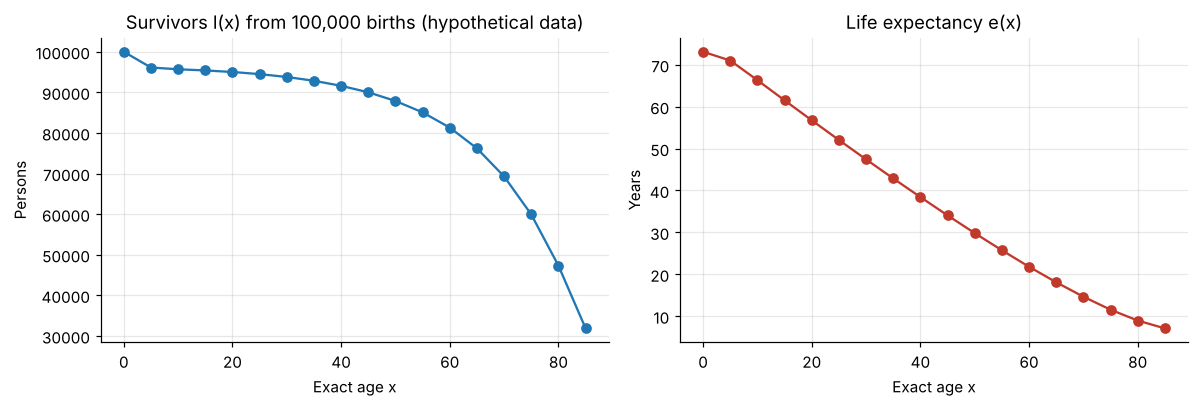

In [10]:
e0, e65 = lt.ex[0], lt.ex[lt.age_start == 65].iloc[0]
l65 = lt.lx[lt.age_start == 65].iloc[0]
chk1 = dx.sum()
chk2 = Tx[0] - (Lx.sum())
trap = [abs(Lx[i] - 2.5 * (lx[i] + lx[i + 1])) for i in range(1, N - 1)]
print(f'e0  = {e0:.2f} years      e65 = {e65:.2f} years')
print(f'Survivors to age 65: l65 = {l65:,.0f} of 100,000 ({l65/1000:.1f}%)')
print(f'\nCheck 1: sum of d_x = {chk1:,.4f}  (must equal radix 100,000)')
print(f'Check 2: T_0 - sum(L_x) = {chk2:.6f}  (must be 0)')
print(f'Check 3: for ages 5-84 (a=2.5), max |L_x - 2.5(l_x + l_x+5)| = {max(trap):.2e}  (L equals the trapezium rule when a=n/2)')
print(f'Check 4: e_85+ = {lt.ex.iloc[-1]:.3f} = 1/m_85+ = {1/lt.mx.iloc[-1]:.3f}')
KEY['lt'] = dict(e0=e0, e65=e65, l65=l65, q0=qx[0], q65=float(lt.qx[lt.age_start==65].iloc[0]), e85=float(lt.ex.iloc[-1]))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(lt.age_start, lt.lx, marker='o'); ax[0].set_title(f'Survivors l(x) from 100,000 births {HYP}'); ax[0].set_xlabel('Exact age x'); ax[0].set_ylabel('Persons')
ax[1].plot(lt.age_start, lt.ex, marker='o', color='#c0392b'); ax[1].set_title('Life expectancy e(x)'); ax[1].set_xlabel('Exact age x'); ax[1].set_ylabel('Years')
fig.tight_layout(); fig.savefig(FIG / 'life_table.png', dpi=150)
life_table.to_csv(OUT / 'life_table.csv', index=False)

Done by BILL MARSHE WAYNE

**Notes: interpretation and checks.**
- **Life expectancy at birth e0 = 73.11 years**: a hypothetical newborn would live 73.1 years on average if the 2025-style mortality rates in this schedule stayed constant (a *period* measure, pooled across sexes, not a forecast).
- **e65 = 18.10 years**: those who reach 65 can expect to live a further 18.1 years, i.e. to about 83.1 on average. Only 76.2% of births survive to 65. Survivors to 65 can expect to die at about 83.1, well above e0 = 73.1, because e0 averages in deaths in infancy and mid-life that 65-year-olds have already survived.
- **Numerical checks:** (1) the sum of d_x equals the radix 100,000; (2) T_0 equals the sum of L_x; (3) for the 5-year bands with a_x = 2.5, L_x equals the trapezium rule 2.5(l_x + l_x+5); (4) e_85+ equals 1/m_85+ (7.092 years). All hold to machine precision.

## 2. Population projections
### Choice of projection district
The brief asks for one of the two contrasting districts to be used for the age-sex projection. I use the **ageing district** (see the next cell for the evidence). Its 2020-2025 trend is *upward*, but the 2025 balance is already *negative* (deaths exceed births and net migration is negative). Simple trend extrapolation therefore points the wrong way, which makes it the most informative case for comparing extrapolation with a cohort-component model. The young district is projected as well (for the dashboard), but the report focuses on the ageing district.

In [11]:
PROJ = SEL_O
pop20 = districts.set_index('district_id').population_2020
pop25 = rec.set_index('district_id').pop2025
pop26 = districts.set_index('district_id').population_2026
cmp = pd.DataFrame({'pop_2020': pop20, 'pop_2025': pop25, 'pop_2026_reported': pop26})
cmp['change_2020_25_pct'] = 100 * (cmp.pop_2025 / cmp.pop_2020 - 1)
cmp['change_2025_26_pct'] = 100 * (cmp.pop_2026_reported / cmp.pop_2025 - 1)
cmp.loc[[SEL_Y, SEL_O]]

,pop_2020,pop_2025,pop_2026_reported,change_2020_25_pct,change_2025_26_pct
district_id,,,,,
D01,156609,172445,173752,10.1118,0.7579
D24,157945,172718,171049,9.3533,-0.9663


**Notes: why the ageing district.** D24 grew 9.4% between 2020 and 2025 but fell 0.97% in 2025 to 2026, so its past trend and current dynamics disagree. That makes it the best test of whether trend extrapolation is adequate. D01 (growth 10.1% then 0.76%) is consistent with its trend.

### 2(a) Arithmetic and geometric growth
With opening counts P(2020) and P(2025) (t = 5 years):
- **Arithmetic:** P(t) = P(2025) + g t, with g = (P2025 - P2020)/5 persons per year
- **Geometric:** P(t) = P(2025)(1 + r)^t, with r = (P2025/P2020)^(1/5) - 1

In [12]:
def trend_models(d):
    p0, p5, p6 = pop20[d], pop25[d], pop26[d]
    g = (p5 - p0) / 5; r = (p5 / p0) ** (1 / 5) - 1
    return dict(district_id=d, P2020=p0, P2025=p5, P2026_reported=p6, arith_annual_change=g, geom_rate=r,
                arith_2026=p5 + g, geom_2026=p5 * (1 + r), arith_2030=p5 + 5 * g, geom_2030=p5 * (1 + r) ** 5)
trend_all = pd.DataFrame([trend_models(d) for d in districts.district_id])
tr = trend_all.set_index('district_id').loc[[PROJ]].T
print(f'Projection district: {PROJ}'); print(tr.to_string())
t = trend_all.set_index('district_id').loc[PROJ]
print(f'\nBack-test against the reported 1 Jan 2026 stock ({t.P2026_reported:,.0f}):')
print(f'  arithmetic 2026 = {t.arith_2026:,.0f} (error {t.arith_2026 - t.P2026_reported:+,.0f});  geometric 2026 = {t.geom_2026:,.0f} (error {t.geom_2026 - t.P2026_reported:+,.0f})')
KEY['trend'] = {k: float(v) for k, v in t.items() if k != 'district_id'}

Projection district: D24
district_id                  D24
P2020                    157,945
P2025                    172,718
P2026_reported           171,049
arith_annual_change   2,954.6000
geom_rate                 0.0180
arith_2026          175,672.6000
geom_2026           175,834.4406
arith_2030               187,491
geom_2030           188,872.7565

Back-test against the reported 1 Jan 2026 stock (171,049):
  arithmetic 2026 = 175,673 (error +4,624);  geometric 2026 = 175,834 (error +4,785)


**Notes: arithmetic and geometric fits (district D24).**
- Arithmetic: +2,955 persons per year, giving **187,491** on 1 January 2030. Geometric: 1.80% per year, giving **188,873**. Geometric exceeds arithmetic slightly because compounding applies to a growing base.
- **Back-test:** applied to 2026, the trend models give 175,673 and 175,834, but the reported 2026 stock is 171,049, so both over-predict by about 4,624 after only one year. The trend models cannot see the reversal because they use only two totals and ignore births, deaths, migration and age structure.

In [13]:
inputs = pd.DataFrame([
    ['population_2020, population_2026', 'Opening stocks on 1 January (counts from the data file)', 'Estimate / observed input'],
    ['population_2025 (sum of age_sex)', 'Opening stock on 1 Jan 2025 derived by summing 36 age-sex cells', 'Estimate (derived)'],
    ['births, deaths, arrivals, departures 2025', 'Calendar-2025 event counts; close the balance exactly', 'Estimate / observed input'],
    ['survival_5yr, newborn_survival_f/m', 'Supplied scenario inputs (not derived from the data)', 'Assumption (input)'],
    ['fertility, arrivals, departures multipliers', 'Scenario scalars applied to 2025 flows', 'Assumption (input)'],
    ['Arithmetic and geometric P(2030)', 'Extrapolate the 2020-25 trend', 'Conditional projection'],
    ['Cohort-component P(2030) by scenario', 'Conditional on survival, fertility, migration and timing assumptions', 'Conditional projection'],
], columns=['Item', 'What it is', 'Classification'])
inputs

,Item,What it is,Classification
0,"population_2020, population_2026",Opening stocks on 1 January (counts from the d...,Estimate / observed input
1,population_2025 (sum of age_sex),Opening stock on 1 Jan 2025 derived by summing...,Estimate (derived)
2,"births, deaths, arrivals, departures 2025",Calendar-2025 event counts; close the balance ...,Estimate / observed input
3,"survival_5yr, newborn_survival_f/m",Supplied scenario inputs (not derived from the...,Assumption (input)
4,"fertility, arrivals, departures multipliers",Scenario scalars applied to 2025 flows,Assumption (input)
5,Arithmetic and geometric P(2030),Extrapolate the 2020-25 trend,Conditional projection
6,Cohort-component P(2030) by scenario,"Conditional on survival, fertility, migration ...",Conditional projection


**Notes: estimates vs conditional projections.** Observed or derived counts (2020, 2025, 2026 stocks and the 2025 events) are *estimates* of past quantities. Survival probabilities, newborn survival and the scenario multipliers are *assumptions supplied as inputs*. Every 2030 number is a *conditional projection*: it is only valid if the stated assumptions hold, and it is not a forecast or a probability statement.

### 2(b) Five-year cohort-component projection (1 Jan 2025 to 1 Jan 2030)
**Timing assumptions (documented):**
1. Each opening cohort is advanced by its supplied five-year survival probability; people aged 80-84 move to 85+, and 85+ retains survivors of the open group.
2. Births over the five years = 5 x (2025 births to women classified by baseline age) x fertility multiplier, split 49% female / 51% male, then multiplied by scenario newborn survival (survival from birth to the end of the interval, averaged over birth dates). Survivors enter ages 0-4.
3. Migration = 5 x each 2025 flow x scenario multiplier, applied as an **end-of-period adjustment** by destination age and sex. Migrants are therefore not exposed to mortality (or fertility) during the interval, and newborns are not exposed to migration.
4. Births are driven by 2025 baseline women. Female cohorts are not re-aged for fertility during the projection (no age-specific fertility feedback).

In [14]:
SCEN = scen.set_index('scenario')

def cohort_component(d, s_row, fert=None, arr=None, dep=None):
    """Return dict with projected age-sex table and accounting components for district d and scenario row s_row (a Series)."""
    fm = s_row.fertility_multiplier if fert is None else fert
    am = s_row.arrivals_multiplier if arr is None else arr
    dm = s_row.departures_multiplier if dep is None else dep
    g = age_sex[age_sex.district_id == d]
    piv = lambda col: g.pivot(index='age_start', columns='sex', values=col).loc[AGES, ['F', 'M']]
    P, S, A, D, B = piv('population_2025'), piv('survival_5yr'), piv('arrivals_2025'), piv('departures_2025'), piv('births_to_women_2025')
    surv = P * S
    adv = pd.DataFrame(0.0, index=AGES, columns=['F', 'M'])
    last = len(AGES) - 1
    for i in range(len(AGES)):
        adv.iloc[min(i + 1, last)] += surv.iloc[i]        # 80-84 -> 85+ ; 85+ -> 85+ (retention)
    births_all = 5 * B['F'].sum() * fm
    births = {'F': 0.49 * births_all, 'M': 0.51 * births_all}
    nb_surv = {'F': births['F'] * s_row.newborn_survival_f, 'M': births['M'] * s_row.newborn_survival_m}
    adv.iloc[0] += pd.Series(nb_surv)
    net_in = 5 * A * am
    net_out = 5 * D * dm
    proj = adv + net_in - net_out
    comp = dict(start=P.values.sum(), cohort_deaths=(P - surv).values.sum(), births=births_all, newborn_deaths=births_all - sum(nb_surv.values()),
                surviving_births=sum(nb_surv.values()), arrivals=net_in.values.sum(), departures=net_out.values.sum(), end=proj.values.sum())
    comp['net_migration'] = comp['arrivals'] - comp['departures']
    comp['end_by_identity'] = comp['start'] - comp['cohort_deaths'] - comp['newborn_deaths'] + comp['births'] + comp['net_migration']
    comp['accounting_gap'] = comp['end'] - comp['end_by_identity']
    comp['min_cell'] = proj.values.min()
    return proj, comp, P

def shares(proj):
    t = proj.values.sum(); u = proj.loc[[0, 5, 10]].values.sum(); o = proj.loc[[a for a in AGES if a >= 65]].values.sum()
    return u / t, o / t

rows = []; proj_store = {}
for s in ['Low', 'Base', 'High']:
    proj, comp, P = cohort_component(PROJ, SCEN.loc[s])
    proj_store[s] = proj
    u, o = shares(proj)
    rows.append(dict(scenario=s, **comp, share_u15=u, share_65p=o, age0_4=proj.loc[0].sum()))
cc = pd.DataFrame(rows).set_index('scenario')
print(f'Cohort-component accounting for {PROJ} (persons, 1 Jan 2025 -> 1 Jan 2030)')
cc[['start', 'cohort_deaths', 'births', 'newborn_deaths', 'surviving_births', 'arrivals', 'departures', 'net_migration', 'end', 'end_by_identity', 'accounting_gap', 'min_cell']].T

Cohort-component accounting for D24 (persons, 1 Jan 2025 -> 1 Jan 2030)


scenario,Low,Base,High
start,"172,718","172,718","172,718"
cohort_deaths,"15,269.2679","15,269.2679","15,269.2679"
births,"9,666.8000","10,985","12,303.2000"
newborn_deaths,324.5145,286.4888,209.8926
surviving_births,"9,342.2855","10,698.5112","12,093.3074"
arrivals,"11,648.1000","14,205","16,761.9000"
departures,"17,298.4000","15,445","13,591.6000"
net_migration,"-5,650.3000","-1,240","3,170.3000"
end,"161,140.7176","166,907.2433","172,712.3395"
end_by_identity,"161,140.7176","166,907.2433","172,712.3395"


**Notes: cohort-component accounting (D24).** Starting from 172,718, the Base scenario removes 15,556 deaths (15,269 among the starting cohorts and 286 among new births), adds 10,985 births and -1,240 net migrants, to reach **166,907**. The decline is driven mainly by natural decrease (-4,571), not by migration. The scenarios differ only through fertility, migration flows and newborn survival (starting cohorts and their survival are identical), spanning 161,141 (Low) to 172,712 (High).

In [15]:
print('Verification of accounting totals:')
for s in cc.index:
    r = cc.loc[s]
    print(f'  {s:4s}: start {r.start:,.0f} - deaths {r.cohort_deaths + r.newborn_deaths:,.0f} + births {r.births:,.0f} + net migration {r.net_migration:+,.0f} = {r.end_by_identity:,.1f};  '
          f'sum of projected cells = {r.end:,.1f};  gap = {r.accounting_gap:.2e};  smallest cell = {r.min_cell:,.0f}')
    assert abs(r.accounting_gap) < 1e-6 and r.min_cell >= 0
print('\nBase scenario projected population by age band and sex, 1 Jan 2030:')
b = proj_store['Base'].copy(); b.index = [AGE_LAB[a] for a in b.index]; b['Total'] = b.sum(axis=1)
b.round(0)

Verification of accounting totals:
  Low : start 172,718 - deaths 15,594 + births 9,667 + net migration -5,650 = 161,140.7;  sum of projected cells = 161,140.7;  gap = 0.00e+00;  smallest cell = 2,046
  Base: start 172,718 - deaths 15,556 + births 10,985 + net migration -1,240 = 166,907.2;  sum of projected cells = 166,907.2;  gap = -2.91e-11;  smallest cell = 2,121
  High: start 172,718 - deaths 15,479 + births 12,303 + net migration +3,170 = 172,712.3;  sum of projected cells = 172,712.3;  gap = 0.00e+00;  smallest cell = 2,195

Base scenario projected population by age band and sex, 1 Jan 2030:


,F,M,Total
0-4,"5,244","5,429","10,674"
5-9,"2,121","2,155","4,276"
10-14,"2,672","2,231","4,903"
15-19,"3,885","3,256","7,142"
20-24,"3,400","3,974","7,374"
25-29,"4,579","3,944","8,523"
30-34,"5,889","4,709","10,598"
35-39,"5,521","5,521","11,043"
40-44,"5,899","5,582","11,481"
45-49,"4,883","4,826","9,709"


**Notes: verification.** For each scenario the independent identity (start - deaths + births + net migration) equals the sum of the 36 projected age-sex cells to within floating-point noise (about 1e-11), and no cell is negative. The smallest projected cell is 2,046 persons, so migration never drives a cohort below zero. The 85+ cell receives survivors from 80-84 and retention from 85+, as specified.

### 2(c) Comparison with trend models, shares, and a one-factor sensitivity

In [16]:
t = trend_all.set_index('district_id').loc[PROJ]
comp_tbl = pd.DataFrame({
    'Projected total 1 Jan 2030': [t.arith_2030, t.geom_2030] + cc.end.tolist(),
    'Share under 15': [np.nan, np.nan] + cc.share_u15.tolist(),
    'Share 65+': [np.nan, np.nan] + cc.share_65p.tolist()},
    index=['Arithmetic', 'Geometric', 'Cohort-component Low', 'Cohort-component Base', 'Cohort-component High'])
comp_tbl['Change vs 2025'] = comp_tbl.iloc[:, 0] - pop25[PROJ]
comp_tbl['Change vs 2025 (%)'] = 100 * comp_tbl['Change vs 2025'] / pop25[PROJ]
comp_tbl['Gap to CC Base'] = comp_tbl.iloc[:, 0] - cc.loc['Base', 'end']
comp_tbl.index.name = f'{PROJ} (opening 2025 = {pop25[PROJ]:,})'
KEY['cc'] = cc.round(4).to_dict('index'); KEY['comp'] = comp_tbl.round(4).to_dict('index')
comp_tbl

,Projected total 1 Jan 2030,Share under 15,Share 65+,Change vs 2025,Change vs 2025 (%),Gap to CC Base
"D24 (opening 2025 = 172,718)",,,,,,
Arithmetic,"187,491",NaN,NaN,"14,773",8.5532,"20,583.7567"
Geometric,"188,872.7565",NaN,NaN,"16,154.7565",9.3533,"21,965.5132"
Cohort-component Low,"161,140.7176",0.1122,0.2772,"-11,577.2824",-6.7030,"-5,766.5257"
Cohort-component Base,"166,907.2433",0.1189,0.2751,"-5,810.7567",-3.3643,0
Cohort-component High,"172,712.3395",0.1255,0.2731,-5.6605,-0.0033,"5,805.0962"


**Notes: comparison of methods.**
- The arithmetic (187,491) and geometric (188,873) results are **20,584 to 21,966 persons above** the Base cohort-component result (166,907). Trend extrapolation says +8.6% to +9.4%, but every cohort-component scenario says decline or stagnation (-6.7% Low, -3.4% Base, -0.00% High). Even the optimistic High scenario produces no growth.
- **Projected shares:** under-15 share rises from 9.7% to 11.2%/11.9%/12.5% (Low/Base/High). The 65+ share is 27.7%/27.5%/27.3%, versus 27.7% now, so the district stays very old. The trend models cannot give shares (they carry no age structure).
- The under-15 increase is partly mechanical. See the data-consistency diagnostic after the sensitivity analysis.

In [17]:
# One-factor sensitivity: Base scenario, change ONLY the fertility multiplier from 1.00 to the High value (1.12)
hi_f = SCEN.loc['High', 'fertility_multiplier']
p_base, c_base, _ = cohort_component(PROJ, SCEN.loc['Base'])
p_sens, c_sens, _ = cohort_component(PROJ, SCEN.loc['Base'], fert=hi_f)
p_high, c_high, _ = cohort_component(PROJ, SCEN.loc['High'])
a_b, a_s, a_h = p_base.loc[0].sum(), p_sens.loc[0].sum(), p_high.loc[0].sum()
sens = pd.DataFrame({'Base': [a_b, c_base['end'], *shares(p_base)], 'Base + High fertility only': [a_s, c_sens['end'], *shares(p_sens)], 'Full High scenario': [a_h, c_high['end'], *shares(p_high)]},
                    index=['Ages 0-4 (persons)', 'Total population', 'Share under 15', 'Share 65+'])
print(sens.to_string())
print(f'\nFertility multiplier 1.00 -> {hi_f:.2f} (+{100*(hi_f-1):.0f}%):')
print(f'  Ages 0-4: {a_b:,.0f} -> {a_s:,.0f}  (change {a_s - a_b:+,.0f} persons, {100*(a_s/a_b-1):+.2f}% )')
print(f'  Surviving births rise by {c_sens["surviving_births"] - c_base["surviving_births"]:,.0f} = 0.12 x Base surviving births {c_base["surviving_births"]:,.0f} = {0.12*c_base["surviving_births"]:,.0f}  (linear, migration unchanged)')
print(f'  Share of the full High-vs-Base gap in ages 0-4 explained by fertility alone: {100*(a_s-a_b)/(a_h-a_b):.1f}%')
KEY['sens'] = dict(a_b=a_b, a_s=a_s, a_h=a_h, delta=a_s - a_b, pct=100 * (a_s / a_b - 1), tot_b=c_base['end'], tot_s=c_sens['end'])

                           Base  Base + High fertility only  Full High scenario
Ages 0-4 (persons)  10,673.5112                 11,957.3325         12,192.8074
Total population   166,907.2433                168,191.0646        172,712.3395
Share under 15           0.1189                      0.1257              0.1255
Share 65+                0.2751                      0.2730              0.2731

Fertility multiplier 1.00 -> 1.12 (+12%):
  Ages 0-4: 10,674 -> 11,957  (change +1,284 persons, +12.03% )
  Surviving births rise by 1,284 = 0.12 x Base surviving births 10,699 = 1,284  (linear, migration unchanged)
  Share of the full High-vs-Base gap in ages 0-4 explained by fertility alone: 84.5%


Done by NEGHANDA Pride

**Notes: fertility sensitivity (Base with only the fertility multiplier changed from 1.00 to 1.12).**
- **Effect:** ages 0-4 rise by **1,284 children (+12.03%)** to 11,957. Because migration and survival are unchanged, the effect is exactly linear: 12% of Base surviving births. The total rises by the same amount, since only the 0-4 cell changes, and still ends below the 2025 starting population.
- Fertility alone explains 84.5% of the High-vs-Base difference in ages 0-4. The rest is higher newborn survival and migration into the age band.
- **One planning implication:** early-childhood, maternity and primary-school capacity in D24 should be planned for a *range* (the extra 1,284 children would, illustratively at 40 pupils per class, need about 32 additional classes in the next primary cohort) and not for a single point. At the same time the total population keeps falling, so child services must be sized separately from the overall population trend.
- **One limitation:** the multiplier is a single scalar on 2025 births. It ignores changes in the age pattern of fertility, the ageing of the female population (women aged 15-49 change over five years, but births are tied to 2025 baseline mothers) and any link between fertility and migration.

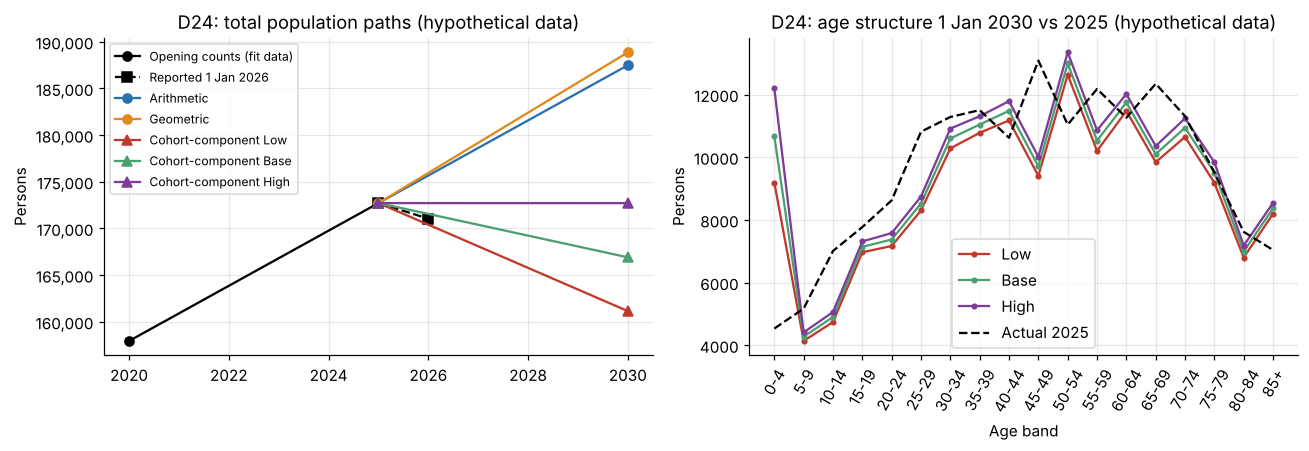

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot([2020, 2025], [pop20[PROJ], pop25[PROJ]], 'ko-', label='Opening counts (fit data)')
ax[0].plot([2025, 2026], [pop25[PROJ], pop26[PROJ]], 'k--', marker='s', label='Reported 1 Jan 2026')
ax[0].plot([2025, 2030], [pop25[PROJ], t.arith_2030], color='#2a6fb0', marker='o', label='Arithmetic')
ax[0].plot([2025, 2030], [pop25[PROJ], t.geom_2030], color='#e08a1e', marker='o', label='Geometric')
for s, c in zip(['Low', 'Base', 'High'], ['#c0392b', '#4c9f70', '#7d3c98']):
    ax[0].plot([2025, 2030], [pop25[PROJ], cc.loc[s, 'end']], color=c, marker='^', label=f'Cohort-component {s}')
ax[0].set_title(f'{PROJ}: total population paths {HYP}'); ax[0].set_ylabel('Persons'); ax[0].legend(fontsize=8)
ax[0].yaxis.set_major_formatter(lambda v, p: f'{v:,.0f}')
for s, c in zip(['Low', 'Base', 'High'], ['#c0392b', '#4c9f70', '#7d3c98']):
    v = proj_store[s].sum(axis=1)
    ax[1].plot([AGE_LAB[a] for a in AGES], v.values, color=c, marker='o', ms=3, label=s)
ax[1].plot([AGE_LAB[a] for a in AGES], age_sex[age_sex.district_id == PROJ].groupby('age_start').population_2025.sum().values, 'k--', label='Actual 2025')
ax[1].set_title(f'{PROJ}: age structure 1 Jan 2030 vs 2025 {HYP}'); ax[1].set_xlabel('Age band'); ax[1].set_ylabel('Persons'); ax[1].tick_params(axis='x', rotation=60); ax[1].legend()
fig.tight_layout(); fig.savefig(FIG / 'projections.png', dpi=150)

**Notes: figures.** The left panel shows the divergence between the trend models and the cohort-component scenarios. The reported 2026 point already lies below the opening 2025 stock, i.e. on the cohort-component side. The right panel shows how the age structure shifts: the 0-4 cell jumps in 2030 and the older ages persist, which leads into the next diagnostic.

In [19]:
# Run the same engine for ALL 24 districts and 3 scenarios (feeds the Power BI district / scenario filter)
tot_rows, ag_rows = [], []
for d in districts.district_id:
    for s in ['Low', 'Base', 'High']:
        pr, cm, _ = cohort_component(d, SCEN.loc[s])
        u, o = shares(pr)
        tot_rows.append(dict(district_id=d, scenario=s, **{k: cm[k] for k in ['start', 'cohort_deaths', 'births', 'newborn_deaths', 'surviving_births', 'arrivals', 'departures', 'net_migration', 'end', 'accounting_gap']},
                             age0_4=pr.loc[0].sum(), share_u15=u, share_65p=o, pct_change=100 * (cm['end'] / cm['start'] - 1)))
        for a in AGES:
            for sx in ['F', 'M']:
                ag_rows.append(dict(district_id=d, scenario=s, age_start=a, age_band=AGE_LAB[a], sex=sx, projected_2030=pr.loc[a, sx]))
proj_tot = pd.DataFrame(tot_rows); proj_age = pd.DataFrame(ag_rows)
print('max |accounting gap| over 72 district-scenario runs:', proj_tot.accounting_gap.abs().max())
proj_tot.to_csv(OUT / 'projection_totals.csv', index=False); proj_age.to_csv(OUT / 'projection_age_sex.csv', index=False); trend_all.to_csv(OUT / 'projection_trend_models.csv', index=False)
proj_tot[proj_tot.district_id.isin([SEL_Y, SEL_O])].round(1)

max |accounting gap| over 72 district-scenario runs: 5.820766091346741e-11


,district_id,scenario,start,cohort_deaths,births,newborn_deaths,surviving_births,arrivals,departures,net_migration,end,accounting_gap,age0_4,share_u15,share_65p,pct_change
0,D01,Low,172445,"9,123","17,331.6000",581.8000,"16,749.8000","10,086","16,385.6000","-6,299.6000","173,772.2000",0,"16,005.3000",0.3000,0.1000,0.8000
1,D01,Base,172445,"9,123","19,695",513.6000,"19,181.4000","12,300","14,630","-2,330","180,173.3000",0,"18,831.4000",0.3000,0.1000,4.5000
2,D01,High,172445,"9,123","22,058.4000",376.3000,"21,682.1000","14,514","12,874.4000","1,639.6000","186,643.7000",0,"21,726.6000",0.3000,0.1000,8.2000
69,D24,Low,172718,"15,269.3000","9,666.8000",324.5000,"9,342.3000","11,648.1000","17,298.4000","-5,650.3000","161,140.7000",0,"9,192.8000",0.1000,0.3000,-6.7000
70,D24,Base,172718,"15,269.3000","10,985",286.5000,"10,698.5000","14,205","15,445","-1,240","166,907.2000",-0,"10,673.5000",0.1000,0.3000,-3.4000
71,D24,High,172718,"15,269.3000","12,303.2000",209.9000,"12,093.3000","16,761.9000","13,591.6000","3,170.3000","172,712.3000",0,"12,192.8000",0.1000,0.3000,-0


**Notes: all districts.** The same engine is run for all 24 districts and 3 scenarios (72 runs). The largest accounting gap is of order 1e-11, i.e. zero. The results are exported for the dashboard's district and scenario filters.

In [20]:
# Data-consistency diagnostic: is "5 x 2025 births" consistent with the observed size of the 0-4 cohort?
c04 = age_sex[(age_sex.district_id == PROJ) & (age_sex.age_start == 0)].population_2025.sum()
b25 = districts.set_index('district_id').births_2025[PROJ]
ratio_all = (5 * districts.set_index('district_id').births_2025 / age_sex[age_sex.age_start == 0].groupby('district_id').population_2025.sum())
implied_mult = (c04 / 5) / b25
p_cons, c_cons, _ = cohort_component(PROJ, SCEN.loc['Base'], fert=implied_mult)
print(f'{PROJ}: observed 0-4 cohort on 1 Jan 2025 = {c04:,}; 5 x 2025 births = {5*b25:,} (ratio {5*b25/c04:.2f})')
print(f'Number of districts where 5 x births exceeds the 0-4 cohort by more than 50%: {(ratio_all > 1.5).sum()} of 24')
print(f'Fertility multiplier that would make 5 x births equal the observed cohort: {implied_mult:.2f}')
print(f'Base projection of ages 0-4 in 2030: {a_b:,.0f} (as specified) vs {p_cons.loc[0].sum():,.0f} (consistency-adjusted); total {c_base["end"]:,.0f} vs {c_cons["end"]:,.0f}')
KEY['cons'] = dict(c04=c04, b5=5 * b25, ratio=5 * b25 / c04, n_dist=int((ratio_all > 1.5).sum()), mult=implied_mult, a04_adj=p_cons.loc[0].sum(), tot_adj=c_cons['end'])

D24: observed 0-4 cohort on 1 Jan 2025 = 4,535; 5 x 2025 births = 10,985 (ratio 2.42)
Number of districts where 5 x births exceeds the 0-4 cohort by more than 50%: 16 of 24
Fertility multiplier that would make 5 x births equal the observed cohort: 0.41
Base projection of ages 0-4 in 2030: 10,674 (as specified) vs 4,392 (consistency-adjusted); total 166,907 vs 160,625


Done by MUTARANI Mishma R

**Notes: data-consistency diagnostic (important caveat).** In D24, five years of births at the 2025 level (10,985) are 2.42 times the observed 0-4 cohort (4,535). Across districts the 0-4 cohort is much smaller than 5 x 2025 births in 16 of 24 districts (for the young group the two agree). So the Base projection's jump in ages 0-4 from 4,535 to 10,674 is **partly mechanical**, a consequence of the prescribed rule "5 x 2025 births", and may reflect either a recent fertility rebound or over-registration of births in the hypothetical data. If births were scaled to match the observed cohort (multiplier 0.41), the 0-4 projection would be about 4,392 and the total 160,625. The brief's method is followed in the main results, but this is reported as a limitation and a validation task before child-service capacity is committed.

## 3. Three-state continuous-time Markov model (Healthy, Ill, Dead)
### 3(a) State diagram, pooled intensities and generator matrix Q
Following the README: `exposure_py` and `initial_lives` are repeated on both destination rows of each district-origin pair. To avoid double counting I take **one copy per district-origin** (a `drop_duplicates` on `district_id, origin`) before pooling, while `transition_count` is summed over all rows.

Intensity estimate (occupancy-exposure, constant-hazard MLE): lambda_ij = (pooled jumps i to j) / (pooled person-years in origin state i).

In [21]:
origin_tbl = ins.drop_duplicates(['district_id', 'origin'])[['district_id', 'origin', 'exposure_py', 'initial_lives']]
naive_expo = ins.groupby('origin').exposure_py.sum()          # WRONG: double counts
expo = origin_tbl.groupby('origin').exposure_py.sum()          # correct
init = origin_tbl.groupby('origin').initial_lives.sum()
cnt = ins.groupby(['origin', 'destination']).transition_count.sum()
print('Pooled exposure (person-years): correct =', expo.to_dict(), '| naive double-counted =', naive_expo.to_dict())
print('Pooled initial lives (counted once per district-origin):', init.to_dict(), '| total =', int(init.sum()))
print('Pooled jump counts:'); print(cnt.to_string())

STATES = ['H', 'I', 'D']
def build_Q(c, e):
    Q = np.zeros((3, 3))
    Q[0, 1] = c[('H', 'I')] / e['H']; Q[0, 2] = c[('H', 'D')] / e['H']
    Q[1, 0] = c[('I', 'H')] / e['I']; Q[1, 2] = c[('I', 'D')] / e['I']
    Q[0, 0] = -Q[0, 1:].sum(); Q[1, 1] = -(Q[1, 0] + Q[1, 2])
    return Q
Q = build_Q(cnt, expo)
Qdf = pd.DataFrame(Q, index=STATES, columns=STATES)
print('\nGenerator matrix Q (per person-year), order H, I, D:'); print(Qdf.round(5).to_string())
print('\nRow sums:', Q.sum(axis=1))
off = Q - np.diag(np.diag(Q))
print('Off-diagonals all >= 0:', bool((off >= 0).all()), '| diagonals all <= 0:', bool((np.diag(Q) <= 0).all()), '| death row all zero (absorbing):', bool((Q[2] == 0).all()))
assert np.allclose(Q.sum(axis=1), 0) and (off >= 0).all()
rates = pd.DataFrame({'jumps': cnt, 'origin_exposure_py': [expo[o] for o, _ in cnt.index]})
rates['intensity_per_py'] = rates.jumps / rates.origin_exposure_py
rates['ci95_low'] = rates.intensity_per_py * (1 - 1.96 / np.sqrt(rates.jumps))
rates['ci95_high'] = rates.intensity_per_py * (1 + 1.96 / np.sqrt(rates.jumps))
rates

Pooled exposure (person-years): correct = {'H': 49764, 'I': 14417} | naive double-counted = {'H': 99528, 'I': 28834}
Pooled initial lives (counted once per district-origin): {'H': 20080, 'I': 3576} | total = 23656
Pooled jump counts:
origin  destination
H       D               895
        I              5152
I       D               970
        H              3533

Generator matrix Q (per person-year), order H, I, D:
        H       I      D
H -0.1215  0.1035 0.0180
I  0.2451 -0.3123 0.0673
D       0       0      0

Row sums: [3.46944695e-18 1.38777878e-17 0.00000000e+00]
Off-diagonals all >= 0: True | diagonals all <= 0: True | death row all zero (absorbing): True


In Colaboration with MVUDUDU Mutsawashe

**Notes: pooled intensities and generator.**
- Counting exposure once per district-origin gives 49,764 healthy person-years and 14,417 ill person-years. A naive sum over the repeated rows would give 99,528 and 28,834, doubling the denominators and **halving every intensity**.
- Intensities per person-year: H to I = 0.1035, H to D = 0.0180, I to H (recovery) = 0.2451, I to D = 0.0673. Mortality from the ill state is 3.7 times mortality from the healthy state.
- **Q checks:** all off-diagonals are non-negative, diagonals are non-positive, each row sums to zero (to ~1e-17) and the D row is zero (absorbing). Pooled initial lives are 20,080 healthy and 3,576 ill (total 23,656).

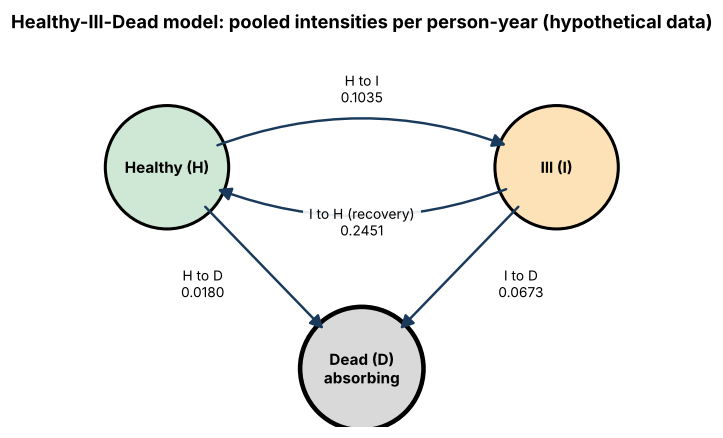

In [22]:
fig, ax = plt.subplots(figsize=(8.5, 4.6)); ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.set_aspect('equal'); ax.axis('off')
pos = {'H': (2, 4), 'I': (8, 4), 'D': (5, 0.9)}
colr = {'H': '#cfe8d5', 'I': '#fde2b8', 'D': '#d9d9d9'}
names = {'H': 'Healthy (H)', 'I': 'Ill (I)', 'D': 'Dead (D)\nabsorbing'}
for s, (x, y) in pos.items():
    ax.add_patch(Circle((x, y), .95, fc=colr[s], ec='k', lw=2 if s != 'D' else 3)); ax.text(x, y, names[s], ha='center', va='center', fontsize=10, fontweight='bold')
def arrow(a, b, rad, label, lx, ly):
    ar = FancyArrowPatch(pos[a], pos[b], connectionstyle=f'arc3,rad={rad}', arrowstyle='-|>', mutation_scale=18, lw=1.6, shrinkA=36, shrinkB=36, color='#1a3a5c'); ax.add_patch(ar)
    ax.text(lx, ly, label, ha='center', fontsize=9, bbox=dict(fc='white', ec='none', alpha=.9))
arrow('H', 'I', -.25, f'H to I\n{Q[0,1]:.4f}', 5, 5.0)
arrow('I', 'H', -.25, f'I to H (recovery)\n{Q[1,0]:.4f}', 5, 2.95)
arrow('H', 'D', .0, f'H to D\n{Q[0,2]:.4f}', 2.55, 2.0)
arrow('I', 'D', .0, f'I to D\n{Q[1,2]:.4f}', 7.45, 2.0)
ax.set_title(f'Healthy-Ill-Dead model: pooled intensities per person-year {HYP}', fontweight='bold')
fig.savefig(FIG / 'markov_diagram.png', dpi=150, bbox_inches='tight')

**Notes: state diagram.** Healthy and Ill communicate (illness and recovery); Dead is absorbing and reachable from both. The arrow labels are the estimated intensities (events per person-year in the origin state).

### 3(b) Holding times and next-jump probabilities
In a continuous-time Markov chain the time spent in state i is exponential with rate -q_ii, so the **mean holding time** is 1/(-q_ii). The **next-jump** destination probabilities are q_ij/(-q_ii).

In [23]:
hold = pd.Series({'H': -1 / Q[0, 0], 'I': -1 / Q[1, 1]}, name='mean holding time (years)')
nj_H = {'I': Q[0, 1] / -Q[0, 0], 'D': Q[0, 2] / -Q[0, 0]}
nj_I = {'H': Q[1, 0] / -Q[1, 1], 'D': Q[1, 2] / -Q[1, 1]}
print('Mean holding times (years):'); print(hold.round(3).to_string())
print('\nNext jump from Ill: P(recovery to H) = {:.4f},  P(death) = {:.4f}  (sum {:.4f})'.format(nj_I['H'], nj_I['D'], sum(nj_I.values())))
print('Next jump from Healthy: P(to I) = {:.4f},  P(to D) = {:.4f}'.format(nj_H['I'], nj_H['D']))

Mean holding times (years):
H   8.2300
I   3.2020

Next jump from Ill: P(recovery to H) = 0.7846,  P(death) = 0.2154  (sum 1.0000)
Next jump from Healthy: P(to I) = 0.8520,  P(to D) = 0.1480


**Notes: holding times and next jump.**
- **Mean holding times:** a healthy life stays healthy for 8.23 years on average (1 / 0.1215); an ill life stays ill for 3.20 years (1 / 0.3123) before the *next* transition.
- **From the ill state the next jump is recovery with probability 0.7846** and death with probability 0.2154. From the healthy state the next jump is to illness with probability 0.8520 and to death with probability 0.1480.

In [24]:
P1 = expm(Q * 1.0); P2 = expm(Q * 2.0)
print(f'Contrast, starting Ill:  P(next jump is recovery) = {nj_I["H"]:.4f}   vs   P(in state H at end of year 1) = {P1[1,0]:.4f}   (P_IH(1))')
print(f'  Starting Ill, state at end of year 1: H {P1[1,0]:.4f}, I {P1[1,1]:.4f}, D {P1[1,2]:.4f}')
print(f'  Probability of having died within the year = {P1[1,2]:.4f}  vs next-jump death probability {nj_I["D"]:.4f}')
KEY['markov'] = dict(Q=Q.tolist(), hold_H=hold['H'], hold_I=hold['I'], rec_next=nj_I['H'], death_next=nj_I['D'], pIH1=P1[1, 0])

Contrast, starting Ill:  P(next jump is recovery) = 0.7846   vs   P(in state H at end of year 1) = 0.1984   (P_IH(1))
  Starting Ill, state at end of year 1: H 0.1984, I 0.7417, D 0.0599
  Probability of having died within the year = 0.0599  vs next-jump death probability 0.2154


**Notes: why "recovery on the next jump" differs from "healthy at the end of one year".** The next-jump probability (0.785) is *conditional on a jump happening* and ignores when it happens. The one-year probability P_IH(1) = **0.198** is a statement at a fixed time. They differ because (i) the mean ill spell lasts 3.2 years, so most ill lives (74.2%) are still ill after one year and have not yet jumped; (ii) a life that recovers can fall ill again (I to H to I) or die later in the year, and only those *in H at exactly one year* count in P_IH(1); and (iii) the next-jump probability ignores the 3-year-long waiting time altogether. In the same way, 21.5% of ill lives *eventually* leave by death on the next jump, but only 6.0% are dead within the year.

### 3(c) Transition matrices by matrix exponential and checks
P(t) = expm(Q t), using `scipy.linalg.expm`.

In [25]:
tol = 1e-10
Pdf1 = pd.DataFrame(P1, index=STATES, columns=STATES); Pdf2 = pd.DataFrame(P2, index=STATES, columns=STATES)
print('P(1):'); print(Pdf1.round(5).to_string()); print('\nP(2):'); print(Pdf2.round(5).to_string())
checks = {
    'P(1) entries non-negative': bool((P1 >= -tol).all()),
    'P(2) entries non-negative': bool((P2 >= -tol).all()),
    'P(1) rows sum to 1 (max error)': float(np.abs(P1.sum(1) - 1).max()),
    'P(2) rows sum to 1 (max error)': float(np.abs(P2.sum(1) - 1).max()),
    'Death absorbing, P(1) row D = (0,0,1)': bool(np.allclose(P1[2], [0, 0, 1])),
    'Death absorbing, P(2) row D = (0,0,1)': bool(np.allclose(P2[2], [0, 0, 1])),
    'max |P(2) - P(1)@P(1)|': float(np.abs(P2 - P1 @ P1).max()),
}
for k, v in checks.items(): print(f'{k:42s}: {v}')
assert np.abs(P2 - P1 @ P1).max() < 1e-10

n0 = np.array([init['H'], init['I'], 0.0])
n1, n2 = n0 @ P1, n0 @ P2
occ = pd.DataFrame([n0, n1, n2], index=['Time 0 (initial)', 'End of year 1', 'End of year 2'], columns=STATES)
occ['Total'] = occ.sum(axis=1)
print('\nExpected occupancy (initial row vector x P(t)):'); print(occ.round(1).to_string())

P(1):
       H      I      D
H 0.8962 0.0838 0.0200
I 0.1984 0.7417 0.0599
D      0      0      1

P(2):
       H      I      D
H 0.8197 0.1373 0.0430
I 0.3250 0.5667 0.1084
D      0      0      1
P(1) entries non-negative                 : True
P(2) entries non-negative                 : True
P(1) rows sum to 1 (max error)            : 0.0
P(2) rows sum to 1 (max error)            : 2.220446049250313e-16
Death absorbing, P(1) row D = (0,0,1)     : True
Death absorbing, P(2) row D = (0,0,1)     : True
max |P(2) - P(1)@P(1)|                    : 2.220446049250313e-16

Expected occupancy (initial row vector x P(t)):
                           H          I        D  Total
Time 0 (initial)      20,080      3,576        0 23,656
End of year 1    18,704.2000 4,335.2000 616.5000 23,656
End of year 2         17,622      4,783    1,251 23,656


**Notes: matrix exponentials and occupancy.**
- P(1) and P(2) come from `scipy.linalg.expm`. All entries are non-negative, rows sum to 1 (max error about 2e-16), the D row is (0, 0, 1) so death is absorbing, and P(2) agrees with P(1)^2 to about 2e-16 (the Chapman-Kolmogorov property).
- **Expected occupancy** (initial row vector x P(t)): after 1 year 18,704 healthy, 4,335 ill, 616.5 dead; after 2 years 17,622 healthy, 4,783 ill, 1,251 dead. The totals always sum to 23,656. The ill group grows (from 3,576 to 4,783) because the inflow from H exceeds recovery and death out of I.

### 3(d) Expected benefit payments
Each covered death triggers USD 1,000. All survivors remain covered and discounting is ignored, so expected deaths in year 1 = D(1) - D(0) and in year 2 = D(2) - D(1), where the initial dead count is 0.

        Expected deaths  Expected benefit payments (USD)
Year 1         616.5000                     616,500.6000
Year 2         634.5000                     634,456.5000
Total             1,251                   1,250,957.2000

Check: total benefit = 1,000 x D(2) = 1,250,957.2
Alive (covered) at end of year 1 and 2: 23039.5 22405.0

90% interval for year-1 benefit: USD 593,766 to 639,731;  year-2 benefit: USD 611,793 to 657,132 (parameter uncertainty only)

Sum over districts reconciles to pooled result: True True


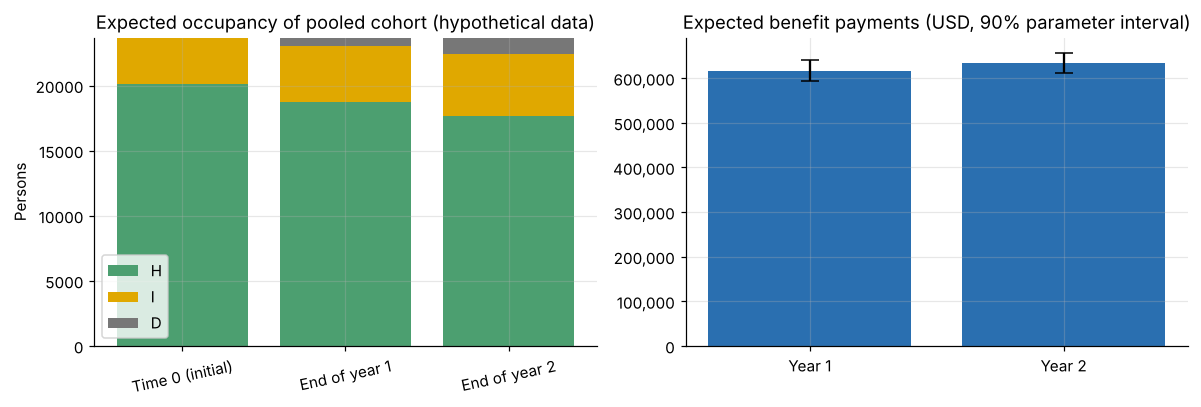

In [26]:
BENEFIT = 1000.0
deaths_y1 = n1[2] - n0[2]; deaths_y2 = n2[2] - n1[2]
claims = pd.DataFrame({'Expected deaths': [deaths_y1, deaths_y2, deaths_y1 + deaths_y2],
                       'Expected benefit payments (USD)': [BENEFIT * deaths_y1, BENEFIT * deaths_y2, BENEFIT * (deaths_y1 + deaths_y2)]}, index=['Year 1', 'Year 2', 'Total'])
print(claims.round(1).to_string())
print(f'\nCheck: total benefit = 1,000 x D(2) = {BENEFIT*n2[2]:,.1f}')
print('Alive (covered) at end of year 1 and 2:', round(n1[:2].sum(), 1), round(n2[:2].sum(), 1))

# Parameter uncertainty (Poisson/Gamma draws for each intensity) -> range for expected claims
rng = np.random.default_rng(2026)
sims = []
for _ in range(3000):
    c = {k: rng.gamma(v, 1.0) for k, v in cnt.items()}
    Qs = build_Q(c, expo)
    a, b = n0 @ expm(Qs), n0 @ expm(2 * Qs)
    sims.append([BENEFIT * a[2], BENEFIT * (b[2] - a[2])])
sims = np.array(sims); lo, hi = np.percentile(sims, [5, 95], axis=0)
print(f'\n90% interval for year-1 benefit: USD {lo[0]:,.0f} to {hi[0]:,.0f};  year-2 benefit: USD {lo[1]:,.0f} to {hi[1]:,.0f} (parameter uncertainty only)')
KEY['claims'] = dict(n0=n0.tolist(), n1=n1.tolist(), n2=n2.tolist(), y1=BENEFIT * deaths_y1, y2=BENEFIT * deaths_y2, lo=lo.tolist(), hi=hi.tolist(), P1=P1.tolist(), P2=P2.tolist())

# By-district split (initial counts of each district x pooled P): feeds the dashboard district filter and reconciles to the pooled answer
dist_rows = []
for d, g in origin_tbl.groupby('district_id'):
    v = np.array([g.loc[g.origin == 'H', 'initial_lives'].iloc[0], g.loc[g.origin == 'I', 'initial_lives'].iloc[0], 0.0])
    a1, a2 = v @ P1, v @ P2
    dist_rows.append(dict(district_id=d, initial_H=v[0], initial_I=v[1], H_end1=a1[0], I_end1=a1[1], D_end1=a1[2], H_end2=a2[0], I_end2=a2[1], D_end2=a2[2],
                          expected_deaths_y1=a1[2], expected_deaths_y2=a2[2] - a1[2], claims_y1_usd=BENEFIT * a1[2], claims_y2_usd=BENEFIT * (a2[2] - a1[2])))
claims_dist = pd.DataFrame(dist_rows)
print('\nSum over districts reconciles to pooled result:', np.isclose(claims_dist.claims_y1_usd.sum(), BENEFIT * deaths_y1), np.isclose(claims_dist.claims_y2_usd.sum(), BENEFIT * deaths_y2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(occ.index, occ.H, label='H', color='#4c9f70'); ax[0].bar(occ.index, occ.I, bottom=occ.H, label='I', color='#e0a800'); ax[0].bar(occ.index, occ.D, bottom=occ.H + occ.I, label='D', color='#777')
ax[0].set_title(f'Expected occupancy of pooled cohort {HYP}'); ax[0].set_ylabel('Persons'); ax[0].legend(); ax[0].tick_params(axis='x', rotation=12)
ax[1].bar(['Year 1', 'Year 2'], [BENEFIT * deaths_y1, BENEFIT * deaths_y2], color='#2a6fb0', yerr=[[BENEFIT*deaths_y1-lo[0], BENEFIT*deaths_y2-lo[1]], [hi[0]-BENEFIT*deaths_y1, hi[1]-BENEFIT*deaths_y2]], capsize=6)
ax[1].set_title('Expected benefit payments (USD, 90% parameter interval)'); ax[1].yaxis.set_major_formatter(lambda v, p: f'{v:,.0f}')
fig.tight_layout(); fig.savefig(FIG / 'markov_claims.png', dpi=150)

**Notes: expected benefit payments.**
- **Year 1: USD 616,501** (616.5 expected deaths). **Year 2: USD 634,457** (634.5 expected deaths). Two-year total USD 1,250,957. Year 2 is higher mainly because the ill population has grown, and ill lives die about 3.7 times faster than healthy lives. The second-year figure is *not* the first-year figure repeated: it is the *increment* D(2) - D(1).
- With parameter uncertainty only, the 90% interval is USD 593,766 to 639,731 in year 1 and USD 611,793 to 657,132 in year 2. It excludes random variation in actual deaths and model error.
- The district split reconciles to the pooled result (district initial counts x the same pooled P).
- **Limitation of pooling constant intensities:** it assumes every insured life, in every district, at every age and every duration of illness, has the same transition rates, and that rates do not change over the two years (a time-homogeneous Markov chain). In reality, mortality and illness rise with age and recovery depends on how long a person has been ill, and districts differ. If the cohort is older or sicker than the pool, claims are understated; the pooled figure can also hide offsetting district differences.

In [27]:
# One-way sensitivity of expected claims to each pooled intensity (+/-20%), holding the others fixed
def claims_for(Qm):
    a, b = n0 @ expm(Qm), n0 @ expm(2 * Qm)
    return BENEFIT * a[2], BENEFIT * (b[2] - a[2])
rows = []
names_ij = {(0, 1): 'H to I (illness onset)', (0, 2): 'H to D', (1, 0): 'I to H (recovery)', (1, 2): 'I to D'}
base_c = claims_for(Q)
for (i, j), nm in names_ij.items():
    for fac in (0.8, 1.2):
        Qs = Q.copy(); Qs[i, j] *= fac; Qs[i, i] = -(Qs[i].sum() - Qs[i, i])
        c1, c2 = claims_for(Qs)
        rows.append(dict(intensity=nm, factor=fac, claims_y1=c1, claims_y2=c2, total_2yr=c1 + c2, change_vs_base_pct=100 * ((c1 + c2) / sum(base_c) - 1)))
tornado = pd.DataFrame(rows)
tornado.to_csv(OUT / 'markov_claims_sensitivity.csv', index=False)
KEY['tornado'] = tornado.round(2).to_dict('records'); KEY['claims']['base_total'] = sum(base_c)
tornado.round(1)

,intensity,factor,claims_y1,claims_y2,total_2yr,change_vs_base_pct
0,H to I (illness onset),0.8000,"607,762.5000","613,145.5000","1,220,908",-2.4000
1,H to I (illness onset),1.2000,"625,124.7000","655,140","1,280,264.7000",2.3000
2,H to D,0.8000,"547,415.8000","571,009.1000","1,118,424.8000",-10.6000
3,H to D,1.2000,"685,343.1000","697,237.1000","1,382,580.2000",10.5000
4,I to H (recovery),0.8000,"620,625.1000","645,895.6000","1,266,520.6000",1.2000
5,I to H (recovery),1.2000,"612,498.1000","623,735.1000","1,236,233.2000",-1.2000
6,I to D,0.8000,"564,155.2000","576,733.6000","1,140,888.9000",-8.8000
7,I to D,1.2000,"668,225.5000","690,440.9000","1,358,666.3000",8.6000


Done by MUDOMBOZI Nyashadzashe

**Notes: sensitivity of claims to the intensities.** Two-year expected claims are driven overwhelmingly by the **death intensities**. A 20% rise in H to D raises claims by 10.5% and a 20% rise in I to D by 8.6%, whereas the same change in illness onset moves claims by only 2.3% and in recovery by -1.2%. The reason is that 84.9% of the cohort starts healthy, so even a small healthy-state death rate generates most claims, while onset and recovery only change claims indirectly (by moving lives between states with different death rates). **Implication:** the accuracy of the two mortality intensities, especially H to D, matters far more for the reserve than the illness dynamics. This is the evidence base for the reserve margin in the insurer's decision.

## 4. District clustering
### 4(a) Data preparation
One row per district with: share under 15, share aged 65+ (1 Jan 2025), 2025 net migration rate (per 1,000 mean-stock residents) and piped-water access (%).

**Imputation rule for the two missing water values (primary fit).** I use a **3-nearest-neighbour imputation on the other three standardised demographic features** (the water value is the average of the 3 most similar districts with observed water). *Justification:* water access is strongly associated with the demographic profile (see the correlations below), so a global mean or median would pull D04 (young profile, probably low access) and D17 (in-migration profile, probably high access) towards the middle and blur the clusters. Neighbour imputation retains all 24 districts, uses only information available for the district, and is transparent. Sensitivity checks with the global median and with dropping water are run in 4(c).

In [28]:
feat = struct[['share_u15', 'share_65p']].copy()
feat['net_migration_rate'] = 1000 * (districts.set_index('district_id').arrivals_2025 - districts.set_index('district_id').departures_2025) / ((pop25 + pop26) / 2)
feat['piped_water_pct'] = districts.set_index('district_id').piped_water_pct
feat = feat.astype(float)
print('Missing values:', feat.isna().sum().to_dict(), '->', feat.index[feat.piped_water_pct.isna()].tolist())
print('\nCorrelation of water with the other features (observed districts only):'); print(feat.corr().piped_water_pct.round(3).to_string())

others = ['share_u15', 'share_65p', 'net_migration_rate']
Z3 = (feat[others] - feat[others].mean()) / feat[others].std(ddof=0)
obs = feat.piped_water_pct.notna()
feat['water_imputed'] = ~obs
feat_imp = feat.copy()
for d in feat.index[~obs]:
    dist = np.sqrt(((Z3[obs] - Z3.loc[d]) ** 2).sum(axis=1)).sort_values()
    nn = dist.index[:3]
    feat_imp.loc[d, 'piped_water_pct'] = feat.loc[nn, 'piped_water_pct'].mean()
    print(f'{d}: nearest neighbours {list(nn)} with water {feat.loc[nn,"piped_water_pct"].tolist()} -> imputed {feat_imp.loc[d,"piped_water_pct"]:.1f}%  (global median would be {feat.piped_water_pct.median():.1f}%)')
FEATS = ['share_u15', 'share_65p', 'net_migration_rate', 'piped_water_pct']
feat_imp[FEATS].describe().T[['count', 'mean', 'std', 'min', 'max']]

Missing values: {'share_u15': 0, 'share_65p': 0, 'net_migration_rate': 0, 'piped_water_pct': 2} -> ['D04', 'D17']

Correlation of water with the other features (observed districts only):
share_u15            -0.6490
share_65p            -0.2250
net_migration_rate    0.8650
piped_water_pct            1
D04: nearest neighbours ['D22', 'D16', 'D13'] with water [44.2, 35.8, 27.7] -> imputed 35.9%  (global median would be 54.0%)
D17: nearest neighbours ['D05', 'D11', 'D08'] with water [77.4, 70.4, 72.9] -> imputed 73.6%  (global median would be 54.0%)


,count,mean,std,min,max
share_u15,24,0.1712,0.0869,0.0903,0.2996
share_65p,24,0.1835,0.0696,0.1222,0.2863
net_migration_rate,24,2.5219,6.8611,-3.9426,13.9906
piped_water_pct,24,56.2319,18.2673,27.7000,86.5000


**Notes: preparation and imputation.**
- Water access is strongly related to the other features (correlation with net migration rate 0.87, with the under-15 share -0.65), so a district-specific imputation is better than one global value.
- The 3-NN rule imputes **D04 = 35.9%** (neighbours are young districts with low access) and **D17 = 73.6%** (neighbours are in-migration districts with high access). A global median (54.0%) would have put both in the middle of the range, where no cluster actually sits. Both imputed values are flagged and treated with caution in the profiles.

Districts with |z| > 2.5 on any feature: []
Districts outside 1.5xIQR fences on any feature: [] (IQR fences are not informative for a deliberately bimodal/trimodal feature)
Max |z| per feature: {'share_u15': 1.51, 'share_65p': 1.51, 'net_migration_rate': 1.71, 'piped_water_pct': 1.69}
Standardised matrix: means [0.0, 0.0, 0.0, 0.0]  sd [1.0, 1.0, 1.0, 1.0]


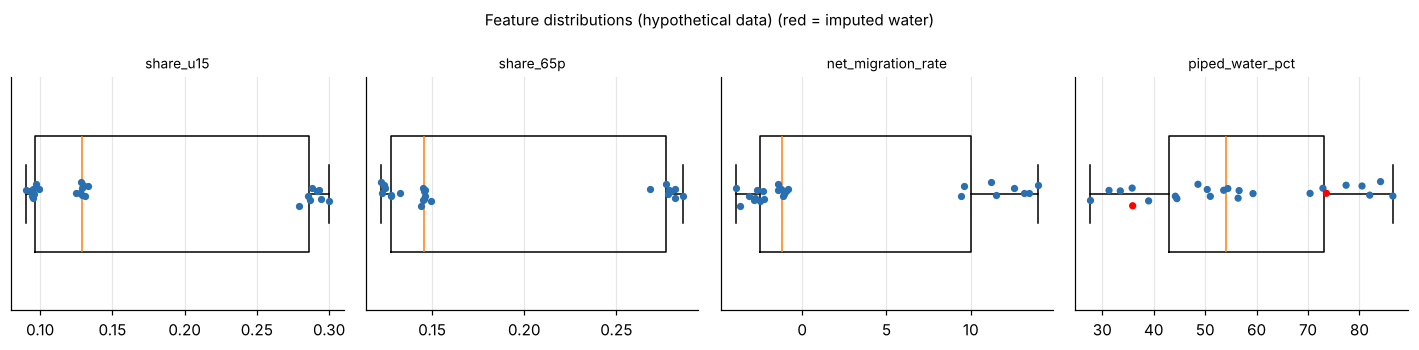

In [29]:
# Outlier checks on the imputed feature set: |z| > 2.5 and Tukey 1.5 x IQR fences
scaler = StandardScaler()
Xz = pd.DataFrame(scaler.fit_transform(feat_imp[FEATS]), index=feat_imp.index, columns=FEATS)
q1, q3 = feat_imp[FEATS].quantile(.25), feat_imp[FEATS].quantile(.75); iqr = q3 - q1
fence = ((feat_imp[FEATS] < q1 - 1.5 * iqr) | (feat_imp[FEATS] > q3 + 1.5 * iqr))
print('Districts with |z| > 2.5 on any feature:', Xz.index[(Xz.abs() > 2.5).any(axis=1)].tolist())
print('Districts outside 1.5xIQR fences on any feature:', fence.index[fence.any(axis=1)].tolist(), '(IQR fences are not informative for a deliberately bimodal/trimodal feature)')
print('Max |z| per feature:', Xz.abs().max().round(2).to_dict())
print('Standardised matrix: means', Xz.mean().round(6).tolist(), ' sd', Xz.std(ddof=0).round(6).tolist())
fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
for a, c in zip(ax, FEATS):
    a.boxplot(feat_imp[c], vert=False, widths=.5); a.scatter(feat_imp[c], np.random.default_rng(1).normal(1, .04, len(feat_imp)), s=14, c=np.where(feat.water_imputed, 'red', '#2a6fb0') if c == 'piped_water_pct' else '#2a6fb0', zorder=3); a.set_title(c, fontsize=9); a.set_yticks([])
fig.suptitle(f'Feature distributions {HYP} (red = imputed water)', fontsize=10); fig.tight_layout()

**Notes: outliers and standardisation.** No district has |z| > 2.5 (largest |z| = 1.71), and none falls outside the 1.5 x IQR fences, so **no district is removed or winsorised**. Standardisation (mean 0, standard deviation 1) is essential: raw net migration (-4 to +14) and water access (28 to 87) would otherwise dominate the two shares (0.09 to 0.30) in Euclidean distance.

**Why the district identifier is excluded.** `district_id` (D01 to D24) is a label, not a measurement. Treated as a number its order is arbitrary and would inject meaningless distance (D01 would look "close" to D02 only because of the sort order); one-hot encoding would make every district equidistant from every other and add 24 uninformative dimensions. Clusters should come from demographic and service features only. The ID is used afterwards to *label* the results. `region` is also excluded from the fit because it is a reporting label; it is cross-tabulated afterwards as a validity check.

### 4(b) k-means diagnostics, k = 1 to 6
Each fit uses `n_init = 25` random initialisations and keeps the lowest within-cluster sum of squares (WCSS). Silhouette is undefined for k = 1.

,k,WCSS,reduction_from_previous_%,mean_silhouette,min_cluster_size
0,1,96,NaN,NaN,24
1,2,42.7161,55.5041,0.5950,8
2,3,2.5675,93.9894,0.8639,8
3,4,1.6048,37.4972,0.7834,4
4,5,1.0390,35.2557,0.6372,3
5,6,0.8082,22.2177,0.4739,3


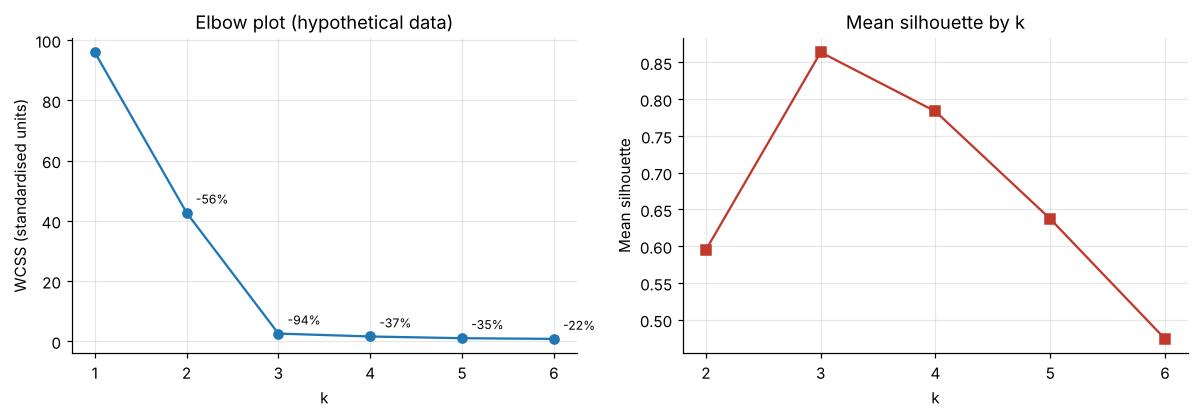

In [30]:
X = Xz.values
fits = {k: KMeans(n_clusters=k, n_init=25, random_state=42).fit(X) for k in range(1, 7)}
diag = pd.DataFrame({'k': list(fits), 'WCSS': [f.inertia_ for f in fits.values()]})
diag['reduction_from_previous_%'] = 100 * (1 - diag.WCSS / diag.WCSS.shift(1))
diag['mean_silhouette'] = [np.nan] + [silhouette_score(X, fits[k].labels_) for k in range(2, 7)]
diag['min_cluster_size'] = [np.bincount(f.labels_).min() for f in fits.values()]
diag.to_csv(OUT / 'cluster_diagnostics.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
ax[0].plot(diag.k, diag.WCSS, 'o-'); ax[0].set_xlabel('k'); ax[0].set_ylabel('WCSS (standardised units)'); ax[0].set_title(f'Elbow plot {HYP}')
for k, w, r in zip(diag.k, diag.WCSS, diag['reduction_from_previous_%']):
    if k > 1: ax[0].annotate(f'-{r:.0f}%', (k, w), textcoords='offset points', xytext=(6, 6), fontsize=8)
ax[0].set_xticks(range(1, 7)); ax[1].set_xticks(range(2, 7)); ax[1].plot(diag.k[1:], diag.mean_silhouette[1:], 's-', color='#c0392b'); ax[1].set_xlabel('k'); ax[1].set_ylabel('Mean silhouette'); ax[1].set_title('Mean silhouette by k')
fig.tight_layout(); fig.savefig(FIG / 'cluster_diagnostics.png', dpi=150)
diag

**Notes: WCSS and silhouette.**
- **WCSS** measures within-cluster compactness (the sum of squared distances to the centroid). It *always* falls as k rises (it is 96 at k=1, the total variation of 24 districts x 4 standardised features), so you look for an elbow, not a minimum. The percentage reductions are 55.5% (k=2), **94.0% (k=3)**, then 37.5%, 35.3%, 22.2%. The drop at k=3 is by far the largest and gains after that are small, so the elbow is at k=3.
- **Mean silhouette** (k=2 to 6): 0.595, **0.864**, 0.783, 0.637, 0.474. It peaks at k=3.

k=3: mean silhouette 0.864; min 0.794; districts with silhouette < 0.25: 0; negative: 0
k=4: mean silhouette 0.783; min 0.476; districts with silhouette < 0.25: 0; negative: 0


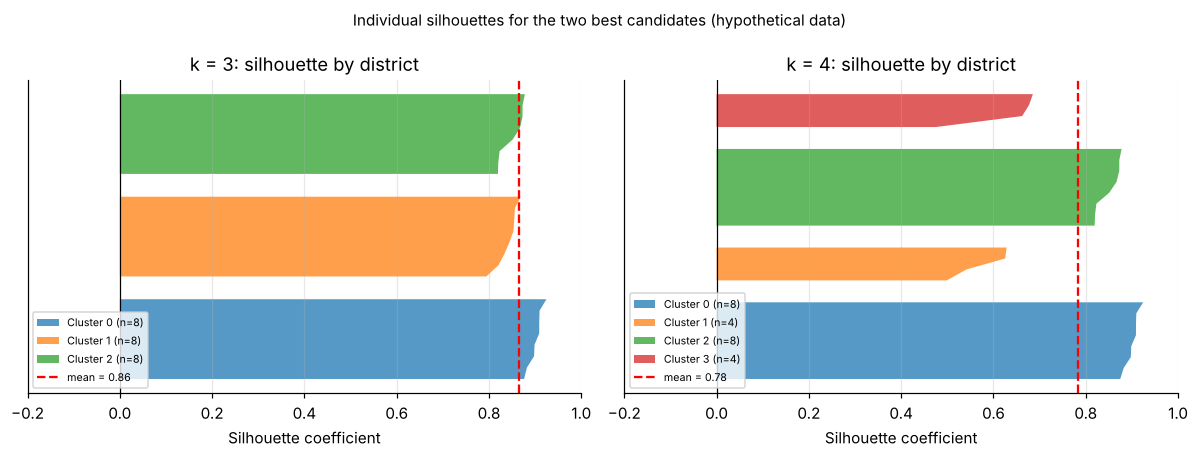

In [31]:
def silhouette_plot(k, ax):
    lab = fits[k].labels_; s = silhouette_samples(X, lab); y0 = 0
    for c in range(k):
        sc = np.sort(s[lab == c]); ax.fill_betweenx(np.arange(y0, y0 + len(sc)), 0, sc, alpha=.75, label=f'Cluster {c} (n={len(sc)})'); y0 += len(sc) + 1
    ax.axvline(s.mean(), color='r', ls='--', label=f'mean = {s.mean():.2f}'); ax.axvline(0, color='k', lw=.8)
    ax.set_title(f'k = {k}: silhouette by district'); ax.set_xlabel('Silhouette coefficient'); ax.set_yticks([]); ax.legend(fontsize=7, loc='lower left'); ax.set_xlim(-.2, 1)
cand = diag.iloc[1:].sort_values('mean_silhouette', ascending=False).k.head(2).astype(int).tolist()
cand = sorted(cand)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for k, a in zip(cand, axes): silhouette_plot(k, a)
fig.suptitle(f'Individual silhouettes for the two best candidates {HYP}', fontsize=10); fig.tight_layout(); fig.savefig(FIG / 'cluster_silhouettes.png', dpi=150)
for k in cand:
    s = silhouette_samples(X, fits[k].labels_)
    print(f'k={k}: mean silhouette {s.mean():.3f}; min {s.min():.3f}; districts with silhouette < 0.25: {int((s<.25).sum())}; negative: {int((s<0).sum())}')

**Notes: individual silhouettes.** A silhouette compares each district's closeness to its own cluster with its closeness to the nearest other cluster. Values near +1 mean a well-matched district; **values near zero mean a boundary district** that could belong to either cluster; **negative values mean the district is nearer another cluster than its own**, a sign of mis-assignment or an unnatural split. For k=3 all 24 districts have high silhouettes (minimum 0.794, none negative). At k=4 the minimum falls to 0.476, which shows that one of the three natural groups is being split artificially. At k=2, two distinct groups are forced together (mean 0.595).

### 4(c) Choice of k, stability and profiles

In [32]:
K = 3
base_lab = fits[K].labels_
# ---- stability 1: different seeds
rows = []
for sd in [1, 7, 123, 2026]:
    lab = KMeans(n_clusters=K, n_init=25, random_state=sd).fit_predict(X)
    rows.append(dict(check=f'Different seed (random_state={sd})', n_districts=24, ARI_vs_primary=adjusted_rand_score(base_lab, lab)))
# ---- stability 2: feature selection (drop water, so no imputation needed)
X3 = StandardScaler().fit_transform(feat_imp[others])
lab3 = KMeans(n_clusters=K, n_init=25, random_state=42).fit_predict(X3)
rows.append(dict(check='Drop piped water (3 features)', n_districts=24, ARI_vs_primary=adjusted_rand_score(base_lab, lab3)))
# ---- stability 3: missing-value treatment: global median
fm = feat[FEATS].copy(); fm['piped_water_pct'] = fm.piped_water_pct.fillna(fm.piped_water_pct.median())
labm = KMeans(n_clusters=K, n_init=25, random_state=42).fit_predict(StandardScaler().fit_transform(fm))
rows.append(dict(check='Global-median water imputation', n_districts=24, ARI_vs_primary=adjusted_rand_score(base_lab, labm)))
# ---- stability 4: drop the two districts with missing water (22 common districts)
keep = obs.values
lab22 = KMeans(n_clusters=K, n_init=25, random_state=42).fit_predict(StandardScaler().fit_transform(feat[FEATS][keep]))
rows.append(dict(check='Listwise deletion of D04, D17', n_districts=int(keep.sum()), ARI_vs_primary=adjusted_rand_score(base_lab[keep], lab22)))
# ---- stability 5: neighbouring k (does k=4 split a coherent group?)
lab4 = fits[4].labels_
rows.append(dict(check='k = 4 vs k = 3 (partition refinement)', n_districts=24, ARI_vs_primary=adjusted_rand_score(base_lab, lab4)))
stab = pd.DataFrame(rows)
KEY['stab'] = stab.round(4).to_dict('records')
stab

,check,n_districts,ARI_vs_primary
0,Different seed (random_state=1),24,1
1,Different seed (random_state=7),24,1
2,Different seed (random_state=123),24,1
3,Different seed (random_state=2026),24,1
4,Drop piped water (3 features),24,1
5,Global-median water imputation,24,1
6,"Listwise deletion of D04, D17",22,1
7,k = 4 vs k = 3 (partition refinement),24,0.8553


**Notes: choice of k and stability.**
- **Chosen k = 3.** *Diagnostics:* largest WCSS elbow (-94%) and highest mean silhouette (0.864), with no weak districts. *Demographic meaning:* the three clusters correspond to recognisable development profiles (young and fast-growing; working-age with in-migration and good services; old and shrinking). k=2 merges two of these, and k=4 creates a cluster of only 4 districts without a clear new demographic story.
- **Stability:** the partition is identical (ARI = 1) under four different seeds, after dropping water, after global-median imputation, and after deleting the two districts with missing water (compared on the 22 common districts, which needs no label matching). The k=4 comparison is lower because it refines the k=3 partition. Membership is therefore not an artefact of the seed, of the imputation rule or of including water.

In [33]:
res = feat_imp[FEATS + ['water_imputed']].copy(); res['cluster_raw'] = base_lab
cen_raw = res.groupby('cluster_raw')[FEATS].mean()
order = {}
young = cen_raw.share_u15.idxmax(); old = cen_raw.share_65p.idxmax(); rest = [c for c in cen_raw.index if c not in (young, old)][0]
order = {young: 'C1 Young, natural-increase', rest: 'C2 Working-age, in-migration, well-served', old: 'C3 Ageing, net out-migration'}
res['cluster'] = res.cluster_raw.map(order)
res['region'] = districts.set_index('district_id').region
res['silhouette'] = silhouette_samples(X, base_lab)
cent = res.groupby('cluster')[FEATS].mean(); cent.insert(0, 'n_districts', res.groupby('cluster').size())
cent['piped_water_pct (observed only)'] = feat.groupby(res.cluster).piped_water_pct.mean()
cent['mean_silhouette'] = res.groupby('cluster').silhouette.mean()
print('Cluster sizes and centroids in ORIGINAL units (primary fit, k=3):'); print(cent.round(3).to_string())
inv = pd.DataFrame(scaler.inverse_transform(fits[K].cluster_centers_), columns=FEATS, index=[order[i] for i in range(K)]).loc[cent.index]
print('\nCheck: centroids from inverse_transform equal group means:', np.allclose(inv.values, cent[FEATS].values))
print('\nMembership:'); [print(f'  {c}: ', ', '.join(res.index[res.cluster == c])) for c in cent.index]
print('\nRegion vs cluster (clusters are not simply the reporting regions):'); print(pd.crosstab(res.cluster, res.region).to_string())
KEY['clusters'] = dict(centroids=cent.round(4).to_dict('index'), members={c: res.index[res.cluster == c].tolist() for c in cent.index}, imputed=feat_imp.loc[~obs, 'piped_water_pct'].round(1).to_dict(),
                       diag=diag.round(4).to_dict('records'))

Cluster sizes and centroids in ORIGINAL units (primary fit, k=3):
                                           n_districts  share_u15  share_65p  net_migration_rate  piped_water_pct  piped_water_pct (observed only)  mean_silhouette
cluster                                                                                                                                                            
C1 Young, natural-increase                           8     0.2900     0.1460             -2.7580          36.4880                          36.5710           0.8500
C2 Working-age, in-migration, well-served            8     0.1290     0.1260             11.8600          78.4210                          79.1140           0.8410
C3 Ageing, net out-migration                         8     0.0950     0.2790             -1.5360          53.7880                          53.7880           0.9010

Check: centroids from inverse_transform equal group means: True

Membership:
  C1 Young, natural-increase:  D01, 

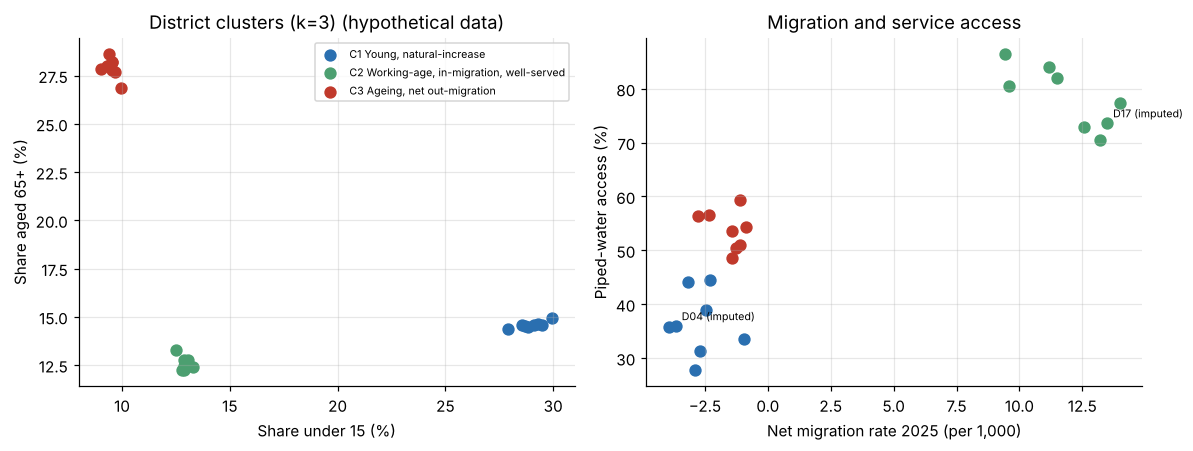

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
pal = {'C1 Young, natural-increase': '#2a6fb0', 'C2 Working-age, in-migration, well-served': '#4c9f70', 'C3 Ageing, net out-migration': '#c0392b'}
for c, g in res.groupby('cluster'):
    ax[0].scatter(g.share_u15 * 100, g.share_65p * 100, c=pal[c], label=c, s=50)
    ax[1].scatter(g.net_migration_rate, g.piped_water_pct, c=pal[c], s=50, marker='o')
    for d in g.index[g.water_imputed]: ax[1].annotate(d + ' (imputed)', (g.loc[d, 'net_migration_rate'], g.loc[d, 'piped_water_pct']), fontsize=7, xytext=(4, 4), textcoords='offset points')
ax[0].set_xlabel('Share under 15 (%)'); ax[0].set_ylabel('Share aged 65+ (%)'); ax[0].legend(fontsize=7); ax[0].set_title(f'District clusters (k=3) {HYP}')
ax[1].set_xlabel('Net migration rate 2025 (per 1,000)'); ax[1].set_ylabel('Piped-water access (%)'); ax[1].set_title('Migration and service access')
fig.tight_layout(); fig.savefig(FIG / 'clusters.png', dpi=150)
res.reset_index().to_csv(OUT / 'cluster_results.csv', index=False); cent.reset_index().to_csv(OUT / 'cluster_centroids.csv', index=False)

Done by NEGHANDA Pride

**Notes: cluster profiles (original units).**
- **C1, Young, natural-increase (n=8):** under-15 29.0%, 65+ 14.6%, net migration -2.8 per 1,000, piped water 36.5%. **C2, Working-age, in-migration, well-served (n=8):** 12.9%, 12.6%, 11.9, 78.4%. **C3, Ageing, net out-migration (n=8):** 9.5%, 27.9%, -1.5, 53.8%.
- Each cluster has members from all four reporting regions, so the profiles are not just administrative regions.
- **One use:** targeting package-based planning, for example water and school/maternal-health investment in C1, housing and infrastructure for newcomers in C2, and elderly-care and health-access planning in C3. A new district can be assigned to the nearest centroid for a first-pass profile.
- **One limitation:** the profiles are single-year averages of four district-level features. They hide differences within districts and do not show causes (for example, water access might be low because of rural settlement, not young age). The separation here is unusually clean because the data are synthetic, and with only 24 districts a different feature set could change the picture in real data. The two imputed water values (D04 and D17) are the least certain.

## 5. Exports for Power BI and reconciliation figures
Every table the dashboard consumes is written to `outputs/` as CSV (relative paths, UTF-8). The dashboard figures reconciled to Python are listed in `outputs/dashboard_reconciliation.csv`.

In [35]:
dp = districts.set_index('district_id')[['district_name', 'region', 'population_2020', 'population_2026', 'births_2025', 'deaths_2025', 'arrivals_2025', 'departures_2025', 'piped_water_pct']].copy()
dp.insert(2, 'population_2025', pop25)
r_ = rec.set_index('district_id')
dp['baseline_deaths_2025'] = r_.base_deaths; dp['newborn_deaths_implied'] = r_.newborn_deaths_implied
mean_stock = (dp.population_2025 + dp.population_2026) / 2
dp['CBR_per_1000'] = 1000 * dp.births_2025 / mean_stock; dp['CDR_per_1000'] = 1000 * dp.deaths_2025 / mean_stock
dp['NMR_per_1000'] = 1000 * (dp.arrivals_2025 - dp.departures_2025) / mean_stock
dp['growth_pct_2025'] = 100 * (dp.population_2026 / dp.population_2025 - 1)
dp = dp.join(struct[['sex_ratio', 'ydr', 'odr', 'ageing_index', 'share_u15', 'share_65p']].astype(float))
dp['piped_water_pct_filled'] = feat_imp.piped_water_pct; dp['water_imputed'] = feat.water_imputed
dp['cluster'] = res.cluster; dp['selected_for_comparison'] = dp.index.isin([SEL_Y, SEL_O]); dp['hypothetical_data'] = 'Yes - synthetic'
dp.reset_index().to_csv(OUT / 'district_profiles.csv', index=False)
pyr = age_sex.copy(); pyr['age_band'] = pyr.age_start.map(AGE_LAB); pyr['sex_label'] = pyr.sex.map({'F': 'Female', 'M': 'Male'})
pyr['pyramid_value'] = np.where(pyr.sex == 'M', -pyr.population_2025, pyr.population_2025)
pyr.to_csv(OUT / 'pyramid_data.csv', index=False)
pd.DataFrame(Q, index=STATES, columns=STATES).rename_axis('from_state').reset_index().to_csv(OUT / 'markov_generator.csv', index=False)
pm = pd.concat([pd.DataFrame(P, index=STATES, columns=STATES).rename_axis('from_state').reset_index().melt('from_state', var_name='to_state', value_name='probability').assign(horizon_years=h) for h, P in [(1, P1), (2, P2)]])
pm.to_csv(OUT / 'markov_transition_matrices.csv', index=False)
occ_out = occ.reset_index().rename(columns={'index': 'time'}).melt('time', value_vars=STATES, var_name='state', value_name='expected_lives')
occ_out.to_csv(OUT / 'markov_occupancy.csv', index=False)
claims_summary = claims.reset_index().rename(columns={'index': 'period'}); claims_summary.to_csv(OUT / 'markov_claims_summary.csv', index=False)
claims_dist.to_csv(OUT / 'markov_claims_by_district.csv', index=False)
sens.reset_index().rename(columns={'index': 'measure'}).to_csv(OUT / 'projection_sensitivity_selected_district.csv', index=False)
print('Files in outputs/:'); print(*sorted(p.name for p in OUT.glob('*.csv')), sep='\n')

Files in outputs/:
cluster_centroids.csv
cluster_diagnostics.csv
cluster_results.csv
dashboard_reconciliation.csv
data_quality_log.csv
district_profiles.csv
life_table.csv
markov_claims_by_district.csv
markov_claims_sensitivity.csv
markov_claims_summary.csv
markov_generator.csv
markov_occupancy.csv
markov_transition_matrices.csv
projection_age_sex.csv
projection_sensitivity_selected_district.csv
projection_totals.csv
projection_trend_models.csv
pyramid_data.csv


In [36]:
bx = proj_tot[(proj_tot.district_id == PROJ) & (proj_tot.scenario == 'Base')].iloc[0]
recon = pd.DataFrame([
    ['Projected population 1 Jan 2030, Base, ' + PROJ, 'projection_totals.csv[end] (district_id=' + PROJ + ', scenario=Base)', bx.end, 'SUM(end) with district and scenario slicers'],
    ['Projected population 1 Jan 2030, High, ' + PROJ, 'projection_totals.csv[end]', proj_tot[(proj_tot.district_id == PROJ) & (proj_tot.scenario == 'High')].end.iloc[0], 'same measure, scenario = High'],
    ['Expected insured deaths in year 1 (pooled cohort)', 'markov_claims_summary.csv', deaths_y1, 'SUM(expected_deaths_y1) over all districts'],
    ['Expected benefit payments, year 1 (USD)', 'markov_claims_summary.csv', BENEFIT * deaths_y1, 'SUM(claims_y1_usd)'],
    ['Expected benefit payments, year 2 (USD)', 'markov_claims_summary.csv', BENEFIT * deaths_y2, 'SUM(claims_y2_usd)'],
    ['Number of districts in each cluster (k=3)', 'cluster_results.csv', 'C1=8, C2=8, C3=8', 'COUNTROWS by cluster'],
    ['Crude death rate per 1,000, ' + PROJ, 'district_profiles.csv[CDR_per_1000]', dp.loc[PROJ, 'CDR_per_1000'], 'DIVIDE(SUM(deaths_2025), AVERAGE of mean stock) x 1000'],
    ['Total baseline population, all districts', 'district_profiles.csv[population_2025]', int(dp.population_2025.sum()), 'SUM(population_2025)'],
], columns=['figure', 'python_source', 'python_value', 'power_bi_how_to_reproduce'])
recon.to_csv(OUT / 'dashboard_reconciliation.csv', index=False)
KEY['recon'] = recon.astype(str).to_dict('records')
recon

,figure,python_source,python_value,power_bi_how_to_reproduce
0,"Projected population 1 Jan 2030, Base, D24","projection_totals.csv[end] (district_id=D24, s...","166,907.2433",SUM(end) with district and scenario slicers
1,"Projected population 1 Jan 2030, High, D24",projection_totals.csv[end],"172,712.3395","same measure, scenario = High"
2,Expected insured deaths in year 1 (pooled cohort),markov_claims_summary.csv,616.5006,SUM(expected_deaths_y1) over all districts
3,"Expected benefit payments, year 1 (USD)",markov_claims_summary.csv,"616,500.6313",SUM(claims_y1_usd)
4,"Expected benefit payments, year 2 (USD)",markov_claims_summary.csv,"634,456.5391",SUM(claims_y2_usd)
5,Number of districts in each cluster (k=3),cluster_results.csv,"C1=8, C2=8, C3=8",COUNTROWS by cluster
6,"Crude death rate per 1,000, D24",district_profiles.csv[CDR_per_1000],21.0491,"DIVIDE(SUM(deaths_2025), AVERAGE of mean stock..."
7,"Total baseline population, all districts",district_profiles.csv[population_2025],2636363,SUM(population_2025)


Done by MUCHEMWA Ngaakudzwe

**Notes: reconciliation.** The Power BI figures listed here must match these Python values; two or more should be shown side by side on the dashboard reconciliation page. `projection_totals.csv`, `markov_claims_by_district.csv` and `cluster_results.csv` are the tables consumed by the corresponding dashboard pages.

## 6. What-if cell for the recorded presentation
Change **one** value in `WHATIF` and re-run this cell (and, if you changed the Markov factors, re-export). The cell prints the base result, the changed result, and the size and direction of the change.

In [37]:
WHATIF = dict(
    district=PROJ,                      # projection district
    fertility_multiplier=1.12,          # PROJECTION: Base uses 1.00 (High scenario uses 1.12)
    arrivals_multiplier=None,           # None = keep Base value (1.00)
    departures_multiplier=None,
    markov_recovery_factor=1.0,         # MARKOV: multiply the I->H intensity (1.0 = unchanged; try 0.7 or 1.3)
    markov_ill_death_factor=1.0,        # MARKOV: multiply the I->D intensity
    markov_healthy_death_factor=1.0,    # MARKOV: multiply the H->D intensity (claims are most sensitive to this one)
    k=3,                                # CLUSTERING: number of clusters (try 2 or 4)
)
W = WHATIF
# projection
pb, cb, _ = cohort_component(W['district'], SCEN.loc['Base'])
pw, cw, _ = cohort_component(W['district'], SCEN.loc['Base'], fert=W['fertility_multiplier'], arr=W['arrivals_multiplier'], dep=W['departures_multiplier'])
print(f'PROJECTION {W["district"]}: total 2030 {cb["end"]:,.0f} -> {cw["end"]:,.0f} ({cw["end"]-cb["end"]:+,.0f}); ages 0-4 {pb.loc[0].sum():,.0f} -> {pw.loc[0].sum():,.0f} ({pw.loc[0].sum()-pb.loc[0].sum():+,.0f})')
# markov
Qw = Q.copy(); Qw[1, 0] *= W['markov_recovery_factor']; Qw[1, 2] *= W['markov_ill_death_factor']; Qw[0, 2] *= W['markov_healthy_death_factor']; Qw[0, 0] = -(Qw[0, 1] + Qw[0, 2]); Qw[1, 1] = -(Qw[1, 0] + Qw[1, 2])
a1, a2 = n0 @ expm(Qw), n0 @ expm(2 * Qw)
cw1, cw2 = BENEFIT * a1[2], BENEFIT * (a2[2] - a1[2])
print(f'MARKOV: year-1 claims USD {BENEFIT*deaths_y1:,.0f} -> {cw1:,.0f} ({cw1-BENEFIT*deaths_y1:+,.0f});  year-2 claims USD {BENEFIT*deaths_y2:,.0f} -> {cw2:,.0f} ({cw2-BENEFIT*deaths_y2:+,.0f})')
# clustering
kw = KMeans(n_clusters=W['k'], n_init=25, random_state=42).fit(X)
print(f'CLUSTERING: k={W["k"]}: WCSS {kw.inertia_:.3f}, mean silhouette {silhouette_score(X, kw.labels_) if W["k"] > 1 else float("nan"):.3f}, ARI vs k=3 partition = {adjusted_rand_score(base_lab, kw.labels_):.3f}, sizes {np.bincount(kw.labels_).tolist()}')

PROJECTION D24: total 2030 166,907 -> 168,191 (+1,284); ages 0-4 10,674 -> 11,957 (+1,284)
MARKOV: year-1 claims USD 616,501 -> 616,501 (+0);  year-2 claims USD 634,457 -> 634,457 (+0)
CLUSTERING: k=3: WCSS 2.568, mean silhouette 0.864, ARI vs k=3 partition = 1.000, sizes [8, 8, 8]


**Notes: what-if.** As supplied, the cell changes only the Base fertility multiplier to 1.12. The result reproduces the sensitivity in Section 2(c): ages 0-4 and the total each rise by the same amount, and the Markov and clustering lines show no change because their factors are left at the defaults. To demonstrate another assumption, change one entry (for example `markov_healthy_death_factor = 1.2` raises two-year claims by about 10%, as the sensitivity table showed; `markov_recovery_factor = 0.7` raises ill occupancy but changes claims only slightly; `k = 4` gives a lower silhouette) and re-run the cell.

In [38]:
json.dump(KEY, open(OUT / 'key_results.json', 'w'), indent=1, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o))
print('Saved outputs/key_results.json (used by the report builder).')
print('Figures saved:', *sorted(p.name for p in FIG.glob('*.png')))

Saved outputs/key_results.json (used by the report builder).
Figures saved: cluster_diagnostics.png cluster_silhouettes.png clusters.png life_table.png markov_claims.png markov_diagram.png projections.png pyramids.png rates.png
